In [1]:
# ============================================================================
# IEEE ACCESS PAPER: Multi-Task Learning with IndicBERT for Citizen Complaint 
# Categorization and Severity Prediction
# ============================================================================
# CELL 1: IMPORTS AND SETUP

import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, 
    precision_recall_fscore_support,
    confusion_matrix, 
    classification_report,
    f1_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from scipy import stats
from scipy.stats import ttest_ind, f_oneway

import seaborn as sns
import matplotlib.pyplot as plt
import pickle
import logging
from datetime import datetime

# Set style for IEEE Access quality figures
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("✅ All imports completed successfully")
print(f"PyTorch version: {torch.__version__}")
print(f"Transformers version: {__import__('transformers').__version__}")

✅ All imports completed successfully
PyTorch version: 2.5.1+cu121
Transformers version: 4.51.3


In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION
# ============================================================================

class Config:
    """Configuration settings for the project"""
    
    # Model paths
    INDICBERT_PATH = "ai4bharat/indic-bert"
    
    # Training params
    MAX_LENGTH = 128
    BATCH_SIZE = 16
    EPOCHS = 10
    LEARNING_RATE = 2e-5
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    
    # Data paths
    TRAIN_PATH = "train/train.csv"
    DEV_PATH = "dev/dev.csv"
    TEST_PATH = "test/test.csv"
    
    # Output
    OUTPUT_DIR = "results"
    MODEL_DIR = "models"
    VISUALIZATION_DIR = "visualizations"
    
    # HuggingFace token (replace with your token)
    HF_TOKEN = os.getenv("HF_TOKEN")
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Random seed for reproducibility
    SEED = 42

# Create directories
os.makedirs(Config.OUTPUT_DIR, exist_ok=True)
os.makedirs(Config.MODEL_DIR, exist_ok=True)
os.makedirs(Config.VISUALIZATION_DIR, exist_ok=True)

print(f"Device: {Config.DEVICE}")
print(f"Output directory: {Config.OUTPUT_DIR}")
print("✅ Configuration loaded successfully")

Device: cuda
Output directory: results
✅ Configuration loaded successfully


In [3]:
# ============================================================================
# CELL 3: DATA PREPROCESSOR WITH SENTIMENT ANALYSIS
# ============================================================================

class DataPreprocessor:
    """Data preprocessing with sentiment analysis for severity detection"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        self.scaler = StandardScaler()
        self.sentiment_weights = None
        
    def load_data(self):
        """Load and combine datasets"""
        print("Loading data...")
        train_df = pd.read_csv(Config.TRAIN_PATH)
        dev_df = pd.read_csv(Config.DEV_PATH)
        test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(train_df)}")
        print(f"Dev samples: {len(dev_df)}")
        print(f"Test samples: {len(test_df)}")
        
        # Combine for consistent encoding
        full_df = pd.concat([train_df, dev_df, test_df], ignore_index=True)
        return train_df, dev_df, test_df, full_df
    
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
        df["text"] = (
            df["complaint_title"].astype(str) + " " +
            df["text_en"].astype(str) + " " +
            df["Hindi"].astype(str) + " " +
            df["Hinglish"].astype(str)
        )
        
        df = df.dropna(subset=[
            "text", "category_primary", 
            "category_secondary", "severity"
        ])
        
        return df.reset_index(drop=True)
    
    def compute_sentiment_score(self, text):
        """
        Compute sentiment score for severity enhancement
        Returns: value between -1 (negative) and 1 (positive)
        """
        # Comprehensive negative keywords
        negative_words = {
            'emergency': 3, 'urgent': 3, 'critical': 3, 'immediately': 2,
            'asap': 2, 'urgently': 2, 'serious': 2, 'severe': 2,
            'dangerous': 2, 'threat': 2, 'risk': 2, 'panic': 2,
            'crisis': 3, 'problem': 1, 'issue': 1, 'complaint': 1,
            'not working': 2, 'broken': 2, 'damage': 2, 'accident': 2,
            'hurt': 2, 'injured': 2, 'unsafe': 2, 'hazard': 2,
            'frustrated': 1, 'angry': 1, 'disgusting': 1, 'terrible': 1,
            'worst': 1, 'bad': 1, 'awful': 1, 'horrible': 1,
            'stuck': 1, 'trapped': 1, 'blocked': 1, 'flood': 2,
            'leakage': 2, 'overflow': 2, 'smell': 1, 'stink': 1,
            'rotten': 1, 'garbage': 1, 'waste': 1, 'unhygienic': 1,
            'pothole': 1, 'crack': 1, 'uneven': 1, 'danger': 2
        }
        
        positive_words = {
            'good': 1, 'great': 1, 'excellent': 2, 'satisfied': 2,
            'happy': 1, 'thankful': 1, 'grateful': 1, 'appreciate': 1,
            'well': 1, 'nice': 1, 'better': 1, 'improved': 1,
            'fixed': 1, 'resolved': 1, 'working': 1, 'fine': 1
        }
        
        text_lower = text.lower()
        
        # Calculate scores with weights
        negative_score = sum(weight for word, weight in negative_words.items() 
                           if word in text_lower)
        positive_score = sum(weight for word, weight in positive_words.items() 
                           if word in text_lower)
        
        # Normalize sentiment score between -1 and 1
        total_score = negative_score + positive_score
        if total_score == 0:
            return 0.0
        
        sentiment = (negative_score - positive_score) / max(total_score, 1)
        return np.clip(sentiment, -1, 1)
    
    def enhance_severity(self, df):
        """
        Enhance severity labels using sentiment analysis
        Original severity: LOW, MEDIUM, HIGH
        Enhanced severity incorporates sentiment
        """
        print("Computing sentiment scores...")
        df['sentiment_score'] = df['text'].apply(self.compute_sentiment_score)
        
        # Map original severity to numeric
        severity_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
        df['severity_encoded'] = df['severity'].map(severity_mapping)
        
        # Adjust severity based on sentiment
        # High negative sentiment (anger) increases severity
        # High positive sentiment (satisfaction) decreases severity
        def adjust_severity(row):
            sentiment = row['sentiment_score']
            base_severity = row['severity_encoded']
            
            # Adjust based on sentiment threshold
            if sentiment > 0.3:  # Positive sentiment
                adjustment = -1 if base_severity > 0 else 0
            elif sentiment < -0.3:  # Negative sentiment
                adjustment = 1 if base_severity < 2 else 0
            else:  # Neutral sentiment
                adjustment = 0
            
            return min(2, max(0, base_severity + adjustment))
        
        df['enhanced_severity'] = df.apply(adjust_severity, axis=1)
        
        # Map back to labels
        reverse_mapping = {0: 'LOW', 1: 'MEDIUM', 2: 'HIGH'}
        df['enhanced_severity_label'] = df['enhanced_severity'].map(reverse_mapping)
        
        return df
    
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("Preparing labels...")
        
        # Fit encoders on full data
        all_primary = pd.concat([train_df, dev_df, test_df])['category_primary']
        all_subcat = pd.concat([train_df, dev_df, test_df])['category_secondary']
        all_severity = pd.concat([train_df, dev_df, test_df])['enhanced_severity_label']
        
        self.le_primary.fit(all_primary)
        self.le_subcat.fit(all_subcat)
        self.le_severity.fit(all_severity)
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform each dataset
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["enhanced_severity_label"])
        
        return train_df, dev_df, test_df
    
    def process_data(self):
        """Complete data processing pipeline"""
        # Load data
        train_df, dev_df, test_df, full_df = self.load_data()
        
        # Preprocess text
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Enhance severity with sentiment
        train_df = self.enhance_severity(train_df)
        dev_df = self.enhance_severity(dev_df)
        test_df = self.enhance_severity(test_df)
        
        # Prepare labels
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"Final train samples: {len(train_df)}")
        print(f"Final dev samples: {len(dev_df)}")
        print(f"Final test samples: {len(test_df)}")
        
        return train_df, dev_df, test_df

# Test the preprocessor
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data()
print("\n✅ Data preprocessing completed successfully")

Loading data...
Train samples: 8000
Dev samples: 1600
Test samples: 1600
Preprocessing text...
Computing sentiment scores...
Computing sentiment scores...
Computing sentiment scores...
Preparing labels...
Primary categories: 8
Subcategories: 30
Severity levels: 3
Final train samples: 7791
Final dev samples: 1555
Final test samples: 1565

✅ Data preprocessing completed successfully


In [4]:
# ============================================================================
# CELL 4: DATASET AND DATALOADER
# ============================================================================

class ComplaintDataset(Dataset):
    """Custom dataset for complaint classification"""
    
    def __init__(self, df, tokenizer, max_length=128):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = df["sentiment_score"].tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
            "sentiment": torch.tensor(self.sentiment[idx], dtype=torch.float)
        }

def create_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders for all datasets"""
    print("Creating datasets and dataloaders...")
    
    # Create datasets
    train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH)
    dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH)
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH)
    
    # Create dataloaders
    train_loader = DataLoader(
        train_dataset, 
        batch_size=Config.BATCH_SIZE, 
        shuffle=True,
        num_workers=0  # Set to 0 for Windows
    )
    dev_loader = DataLoader(
        dev_dataset, 
        batch_size=Config.BATCH_SIZE,
        num_workers=0
    )
    test_loader = DataLoader(
        test_dataset, 
        batch_size=Config.BATCH_SIZE,
        num_workers=0
    )
    
    print(f"Train batches: {len(train_loader)}")
    print(f"Dev batches: {len(dev_loader)}")
    print(f"Test batches: {len(test_loader)}")
    
    return train_loader, dev_loader, test_loader

# Test dataset creation
# We'll create tokenizer later after loading the model
print("✅ Dataset class defined successfully")

✅ Dataset class defined successfully


In [5]:
# ============================================================================
# CELL 5: LOAD INDICBERT MODEL AND TOKENIZER
# ============================================================================

def load_indicbert_model():
    """Load IndicBERT model and tokenizer"""
    print("Loading IndicBERT model and tokenizer...")
    
    # Load tokenizer
    tokenizer = AutoTokenizer.from_pretrained(
        Config.INDICBERT_PATH,
        token=Config.HF_TOKEN,
        use_fast=False  # Use slow tokenizer for IndicBERT
    )
    
    # Load base model
    base_model = AutoModel.from_pretrained(
        Config.INDICBERT_PATH,
        token=Config.HF_TOKEN
    )
    
    print(f"Model loaded: {Config.INDICBERT_PATH}")
    print(f"Vocabulary size: {tokenizer.vocab_size}")
    print(f"Hidden size: {base_model.config.hidden_size}")
    
    return base_model, tokenizer

# Load model and tokenizer
base_model, tokenizer = load_indicbert_model()

# Move model to device
base_model = base_model.to(Config.DEVICE)

print(f"\n✅ IndicBERT loaded successfully on {Config.DEVICE}")

Loading IndicBERT model and tokenizer...
Model loaded: ai4bharat/indic-bert
Vocabulary size: 200000
Hidden size: 768

✅ IndicBERT loaded successfully on cuda


In [6]:
# ============================================================================
# CELL 6: MULTI-TASK MODEL WITH SENTIMENT ENHANCEMENT
# ============================================================================

class MultiTaskModel(nn.Module):
    """
    Multi-task model with sentiment-enhanced severity prediction
    
    Tasks:
    1. Primary Category Classification
    2. Subcategory Classification
    3. Severity Classification (enhanced with sentiment)
    """
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        # Dropout for regularization
        self.dropout = nn.Dropout(dropout)
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        
        # Severity head: hidden_size + 1 for sentiment feature
        self.fc_severity = nn.Linear(hidden_size + 1, n_severity)
        
        # Store task dimensions
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        """
        Forward pass
        Args:
            input_ids: Token IDs
            attention_mask: Attention mask
            sentiment: Sentiment scores for severity enhancement
        """
        # Get BERT embeddings
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        
        # Apply dropout
        x = self.dropout(cls_embedding)
        
        # Primary and subcategory predictions
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        # Severity prediction with sentiment
        if sentiment is not None:
            # Concatenate sentiment with CLS embedding
            sentiment = sentiment.unsqueeze(1)  # [batch, 1]
            severity_input = torch.cat([x, sentiment], dim=1)  # [batch, hidden+1]
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract embeddings for visualization"""
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]  # [CLS] token

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = MultiTaskModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"Model architecture:")
print(f"  Primary classes: {n_primary}")
print(f"  Subcategory classes: {n_subcat}")
print(f"  Severity classes: {n_severity}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")

print("\n✅ Multi-task model created successfully")

Model architecture:
  Primary classes: 8
  Subcategory classes: 30
  Severity classes: 3
  Total parameters: 33,475,116

✅ Multi-task model created successfully


In [7]:
# ============================================================================
# CELL 7: TRAINING FUNCTIONS
# ============================================================================

class ModelTrainer:
    """Trainer for multi-task model with validation and metrics tracking"""
    
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.history = {
            'train_loss': [],
            'val_loss': [],
            'val_accuracy': [],
            'val_f1': []
        }
        
    def train_epoch(self, train_loader, optimizer, criterion, epoch):
        """Train for one epoch"""
        self.model.train()
        total_loss = 0
        
        for batch_idx, batch in enumerate(train_loader):
            # Move data to device
            input_ids = batch["input_ids"].to(self.device)
            attention_mask = batch["attention_mask"].to(self.device)
            
            y_primary = batch["primary"].to(self.device)
            y_subcat = batch["subcat"].to(self.device)
            y_severity = batch["severity"].to(self.device)
            sentiment = batch["sentiment"].to(self.device)
            
            # Forward pass
            p1, p2, p3 = self.model(input_ids, attention_mask, sentiment)
            
            # Compute losses
            loss1 = criterion(p1, y_primary)
            loss2 = criterion(p2, y_subcat)
            loss3 = criterion(p3, y_severity)
            
            # Weighted combination
            loss = loss1 + loss2 + 0.5 * loss3
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            optimizer.step()
            
            total_loss += loss.item()
            
            if batch_idx % 100 == 0:
                print(f'Epoch {epoch+1}, Batch {batch_idx}, Loss: {loss.item():.4f}')
        
        return total_loss / len(train_loader)
    
    def evaluate(self, val_loader, criterion):
        """Evaluate on validation set"""
        self.model.eval()
        total_loss = 0
        all_preds = []
        all_labels = []
        
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch["input_ids"].to(self.device)
                attention_mask = batch["attention_mask"].to(self.device)
                y_primary = batch["primary"].to(self.device)
                sentiment = batch["sentiment"].to(self.device)
                
                p1, _, _ = self.model(input_ids, attention_mask, sentiment)
                
                # Primary task loss (for monitoring)
                loss = criterion(p1, y_primary)
                total_loss += loss.item()
                
                # Collect predictions
                preds = torch.argmax(p1, dim=1).cpu().numpy()
                labels = y_primary.cpu().numpy()
                all_preds.extend(preds)
                all_labels.extend(labels)
        
        accuracy = accuracy_score(all_labels, all_preds)
        f1 = f1_score(all_labels, all_preds, average='weighted')
        
        return total_loss / len(val_loader), accuracy, f1
    
    def train(self, train_loader, val_loader, epochs=10, lr=2e-5):
        """Complete training loop"""
        print(f"\nStarting training for {epochs} epochs...")
        
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=lr)
        criterion = nn.CrossEntropyLoss()
        
        for epoch in range(epochs):
            # Train
            train_loss = self.train_epoch(train_loader, optimizer, criterion, epoch)
            
            # Validate
            val_loss, val_acc, val_f1 = self.evaluate(val_loader, criterion)
            
            # Store history
            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)
            self.history['val_accuracy'].append(val_acc)
            self.history['val_f1'].append(val_f1)
            
            print(f'Epoch {epoch+1}/{epochs}:')
            print(f'  Train Loss: {train_loss:.4f}')
            print(f'  Val Loss: {val_loss:.4f}')
            print(f'  Val Accuracy: {val_acc:.4f}')
            print(f'  Val F1-Score: {val_f1:.4f}')
            print('-' * 50)
        
        print("\n✅ Training completed successfully")
        return self.history

# Create dataloaders
train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Create trainer
trainer = ModelTrainer(model, Config.DEVICE)
print("\n✅ Trainer initialized successfully")

Creating datasets and dataloaders...
Train batches: 487
Dev batches: 98
Test batches: 98

✅ Trainer initialized successfully


In [8]:
# ============================================================================
# CELL 8: TRAIN THE MODEL
# ============================================================================

# Train the model
history = trainer.train(
    train_loader, 
    dev_loader, 
    epochs=Config.EPOCHS, 
    lr=Config.LEARNING_RATE
)

# Save the model
model_path = f"{Config.MODEL_DIR}/indicbert_multitask_model.pt"
torch.save(model.state_dict(), model_path)
print(f"✅ Model saved to: {model_path}")

# Save encoders
pickle.dump(preprocessor.le_primary, open(f"{Config.MODEL_DIR}/le_primary.pkl", "wb"))
pickle.dump(preprocessor.le_subcat, open(f"{Config.MODEL_DIR}/le_subcat.pkl", "wb"))
pickle.dump(preprocessor.le_severity, open(f"{Config.MODEL_DIR}/le_severity.pkl", "wb"))
print("✅ Encoders saved successfully")


Starting training for 10 epochs...
Epoch 1, Batch 0, Loss: 5.8893
Epoch 1, Batch 100, Loss: 4.3860
Epoch 1, Batch 200, Loss: 3.0126
Epoch 1, Batch 300, Loss: 2.4360
Epoch 1, Batch 400, Loss: 2.1413
Epoch 1/10:
  Train Loss: 2.9554
  Val Loss: 0.6560
  Val Accuracy: 0.8225
  Val F1-Score: 0.8033
--------------------------------------------------
Epoch 2, Batch 0, Loss: 2.3095
Epoch 2, Batch 100, Loss: 1.7528
Epoch 2, Batch 200, Loss: 1.7770
Epoch 2, Batch 300, Loss: 2.3457
Epoch 2, Batch 400, Loss: 1.9601
Epoch 2/10:
  Train Loss: 1.8877
  Val Loss: 0.5761
  Val Accuracy: 0.8386
  Val F1-Score: 0.8238
--------------------------------------------------
Epoch 3, Batch 0, Loss: 2.0013
Epoch 3, Batch 100, Loss: 1.7143
Epoch 3, Batch 200, Loss: 1.3706
Epoch 3, Batch 300, Loss: 1.6466
Epoch 3, Batch 400, Loss: 1.5280
Epoch 3/10:
  Train Loss: 1.6228
  Val Loss: 0.5166
  Val Accuracy: 0.8540
  Val F1-Score: 0.8462
--------------------------------------------------
Epoch 4, Batch 0, Loss: 2.18

In [9]:
# ============================================================================
# CELL 9: MODEL EVALUATION
# ============================================================================

def evaluate_model(model, test_loader, device, preprocessor):
    """Comprehensive evaluation of the model on test set"""
    print("\nEvaluating model on test set...")
    
    model.eval()
    
    # Initialize containers
    primary_preds, primary_labels = [], []
    subcat_preds, subcat_labels = [], []
    severity_preds, severity_labels = [], []
    all_embeddings = []
    all_texts = []
    
    with torch.no_grad():
        for batch_idx, batch in enumerate(test_loader):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            sentiment = batch["sentiment"].to(device)
            
            # Forward pass
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            
            # Get embeddings for visualization
            embeddings = model.get_embeddings(input_ids, attention_mask)
            all_embeddings.append(embeddings.cpu().numpy())
            
            # Primary task
            preds = torch.argmax(p1, dim=1).cpu().numpy()
            labels = batch["primary"].cpu().numpy()
            primary_preds.extend(preds)
            primary_labels.extend(labels)
            
            # Subcategory
            preds = torch.argmax(p2, dim=1).cpu().numpy()
            labels = batch["subcat"].cpu().numpy()
            subcat_preds.extend(preds)
            subcat_labels.extend(labels)
            
            # Severity
            preds = torch.argmax(p3, dim=1).cpu().numpy()
            labels = batch["severity"].cpu().numpy()
            severity_preds.extend(preds)
            severity_labels.extend(labels)
    
    # Convert embeddings
    all_embeddings = np.vstack(all_embeddings)
    
    # Compute metrics
    metrics = {}
    
    # Primary task
    metrics['primary'] = {
        'accuracy': accuracy_score(primary_labels, primary_preds),
        'precision': precision_recall_fscore_support(
            primary_labels, primary_preds, average='weighted'
        )[0],
        'recall': precision_recall_fscore_support(
            primary_labels, primary_preds, average='weighted'
        )[1],
        'f1': f1_score(primary_labels, primary_preds, average='weighted')
    }
    
    # Subcategory
    metrics['subcategory'] = {
        'accuracy': accuracy_score(subcat_labels, subcat_preds),
        'precision': precision_recall_fscore_support(
            subcat_labels, subcat_preds, average='weighted'
        )[0],
        'recall': precision_recall_fscore_support(
            subcat_labels, subcat_preds, average='weighted'
        )[1],
        'f1': f1_score(subcat_labels, subcat_preds, average='weighted')
    }
    
    # Severity
    metrics['severity'] = {
        'accuracy': accuracy_score(severity_labels, severity_preds),
        'precision': precision_recall_fscore_support(
            severity_labels, severity_preds, average='weighted'
        )[0],
        'recall': precision_recall_fscore_support(
            severity_labels, severity_preds, average='weighted'
        )[1],
        'f1': f1_score(severity_labels, severity_preds, average='weighted')
    }
    
    # Print results
    print("\n" + "="*60)
    print("TEST SET PERFORMANCE")
    print("="*60)
    
    for task, task_metrics in metrics.items():
        print(f"\n{task.upper()}:")
        for metric_name, value in task_metrics.items():
            print(f"  {metric_name}: {value:.4f}")
    
    return {
        'metrics': metrics,
        'predictions': {
            'primary': primary_preds,
            'subcat': subcat_preds,
            'severity': severity_preds
        },
        'labels': {
            'primary': primary_labels,
            'subcat': subcat_labels,
            'severity': severity_labels
        },
        'embeddings': all_embeddings
    }

# Evaluate the model
evaluation_results = evaluate_model(
    model, test_loader, Config.DEVICE, preprocessor
)


Evaluating model on test set...

TEST SET PERFORMANCE

PRIMARY:
  accuracy: 0.8671
  precision: 0.8673
  recall: 0.8671
  f1: 0.8648

SUBCATEGORY:
  accuracy: 0.7163
  precision: 0.7005
  recall: 0.7163
  f1: 0.7037

SEVERITY:
  accuracy: 0.8556
  precision: 0.8356
  recall: 0.8556
  f1: 0.8304


Training history plot saved to: visualizations/training_history.png


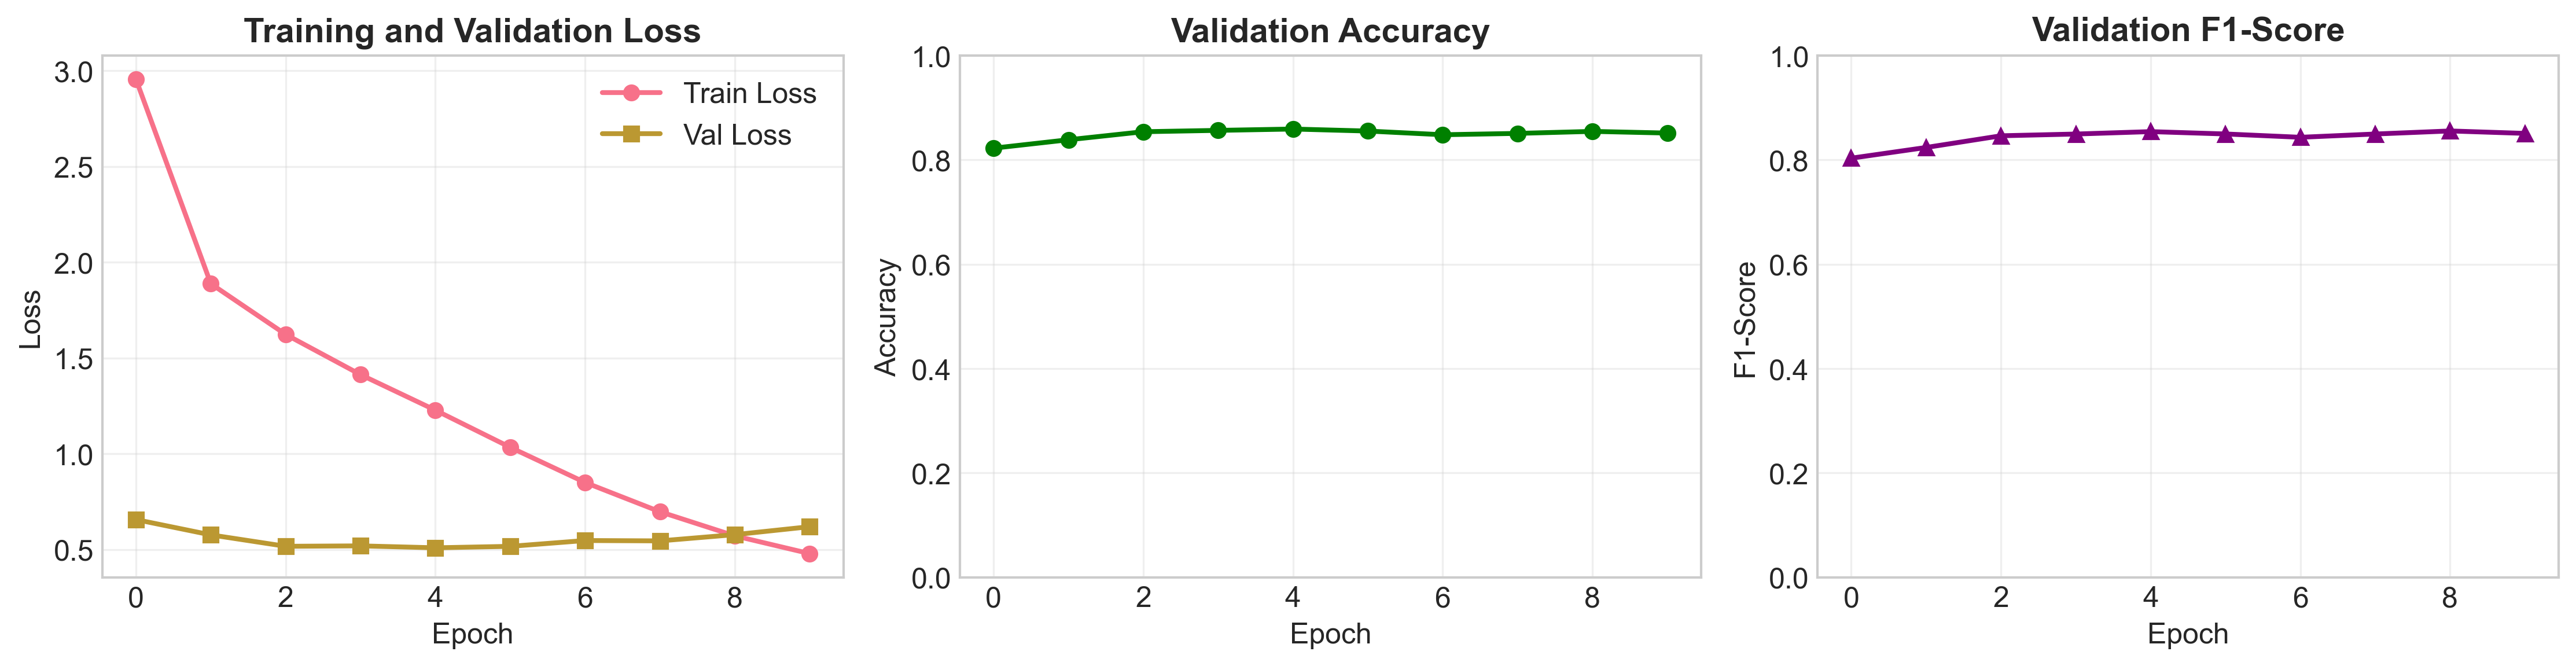

In [10]:
# ============================================================================
# CELL 10: VISUALIZATION - TRAINING HISTORY
# ============================================================================

def plot_training_history(history, save_path=None):
    """Plot training and validation curves"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Training loss
    axes[0].plot(history['train_loss'], label='Train Loss', marker='o', linewidth=2)
    axes[0].plot(history['val_loss'], label='Val Loss', marker='s', linewidth=2)
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training and Validation Loss', fontweight='bold')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Validation accuracy
    axes[1].plot(history['val_accuracy'], label='Val Accuracy', marker='o', 
                color='green', linewidth=2)
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_title('Validation Accuracy', fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].set_ylim(0, 1)
    
    # Validation F1-score
    axes[2].plot(history['val_f1'], label='Val F1-Score', marker='^', 
                color='purple', linewidth=2)
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('F1-Score')
    axes[2].set_title('Validation F1-Score', fontweight='bold')
    axes[2].grid(True, alpha=0.3)
    axes[2].set_ylim(0, 1)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Training history plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Plot and save
plot_training_history(
    trainer.history, 
    save_path=f"{Config.VISUALIZATION_DIR}/training_history.png"
)

In [11]:
# ============================================================================
# CELL 11: VISUALIZATION - CONFUSION MATRICES
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, labels, title, filename, save_dir):
    """Plot confusion matrix with raw and normalized versions"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    # Handle NaN in normalized matrix
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
               xticklabels=labels, yticklabels=labels, ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontweight='bold')
    axes[0].set_xlabel('Predicted')
    axes[0].set_ylabel('Actual')
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
               xticklabels=labels, yticklabels=labels, ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontweight='bold')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Actual')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    plt.savefig(f"{save_dir}/{filename}.png", dpi=300, bbox_inches='tight')
    plt.close()

# Plot confusion matrices
le_primary = preprocessor.le_primary
le_subcat = preprocessor.le_subcat
le_severity = preprocessor.le_severity

# Primary task
plot_confusion_matrix(
    evaluation_results['labels']['primary'],
    evaluation_results['predictions']['primary'],
    le_primary.classes_,
    'Primary Category',
    'confusion_primary',
    Config.VISUALIZATION_DIR
)

# Subcategory task
plot_confusion_matrix(
    evaluation_results['labels']['subcat'],
    evaluation_results['predictions']['subcat'],
    le_subcat.classes_,
    'Subcategory',
    'confusion_subcat',
    Config.VISUALIZATION_DIR
)

# Severity task
plot_confusion_matrix(
    evaluation_results['labels']['severity'],
    evaluation_results['predictions']['severity'],
    le_severity.classes_,
    'Severity',
    'confusion_severity',
    Config.VISUALIZATION_DIR
)

print("✅ Confusion matrices saved successfully")

✅ Confusion matrices saved successfully


Computing t-SNE embeddings...
t-SNE completed. Output shape: (1000, 2)
t-SNE plot saved to: visualizations/tsne_embeddings.png


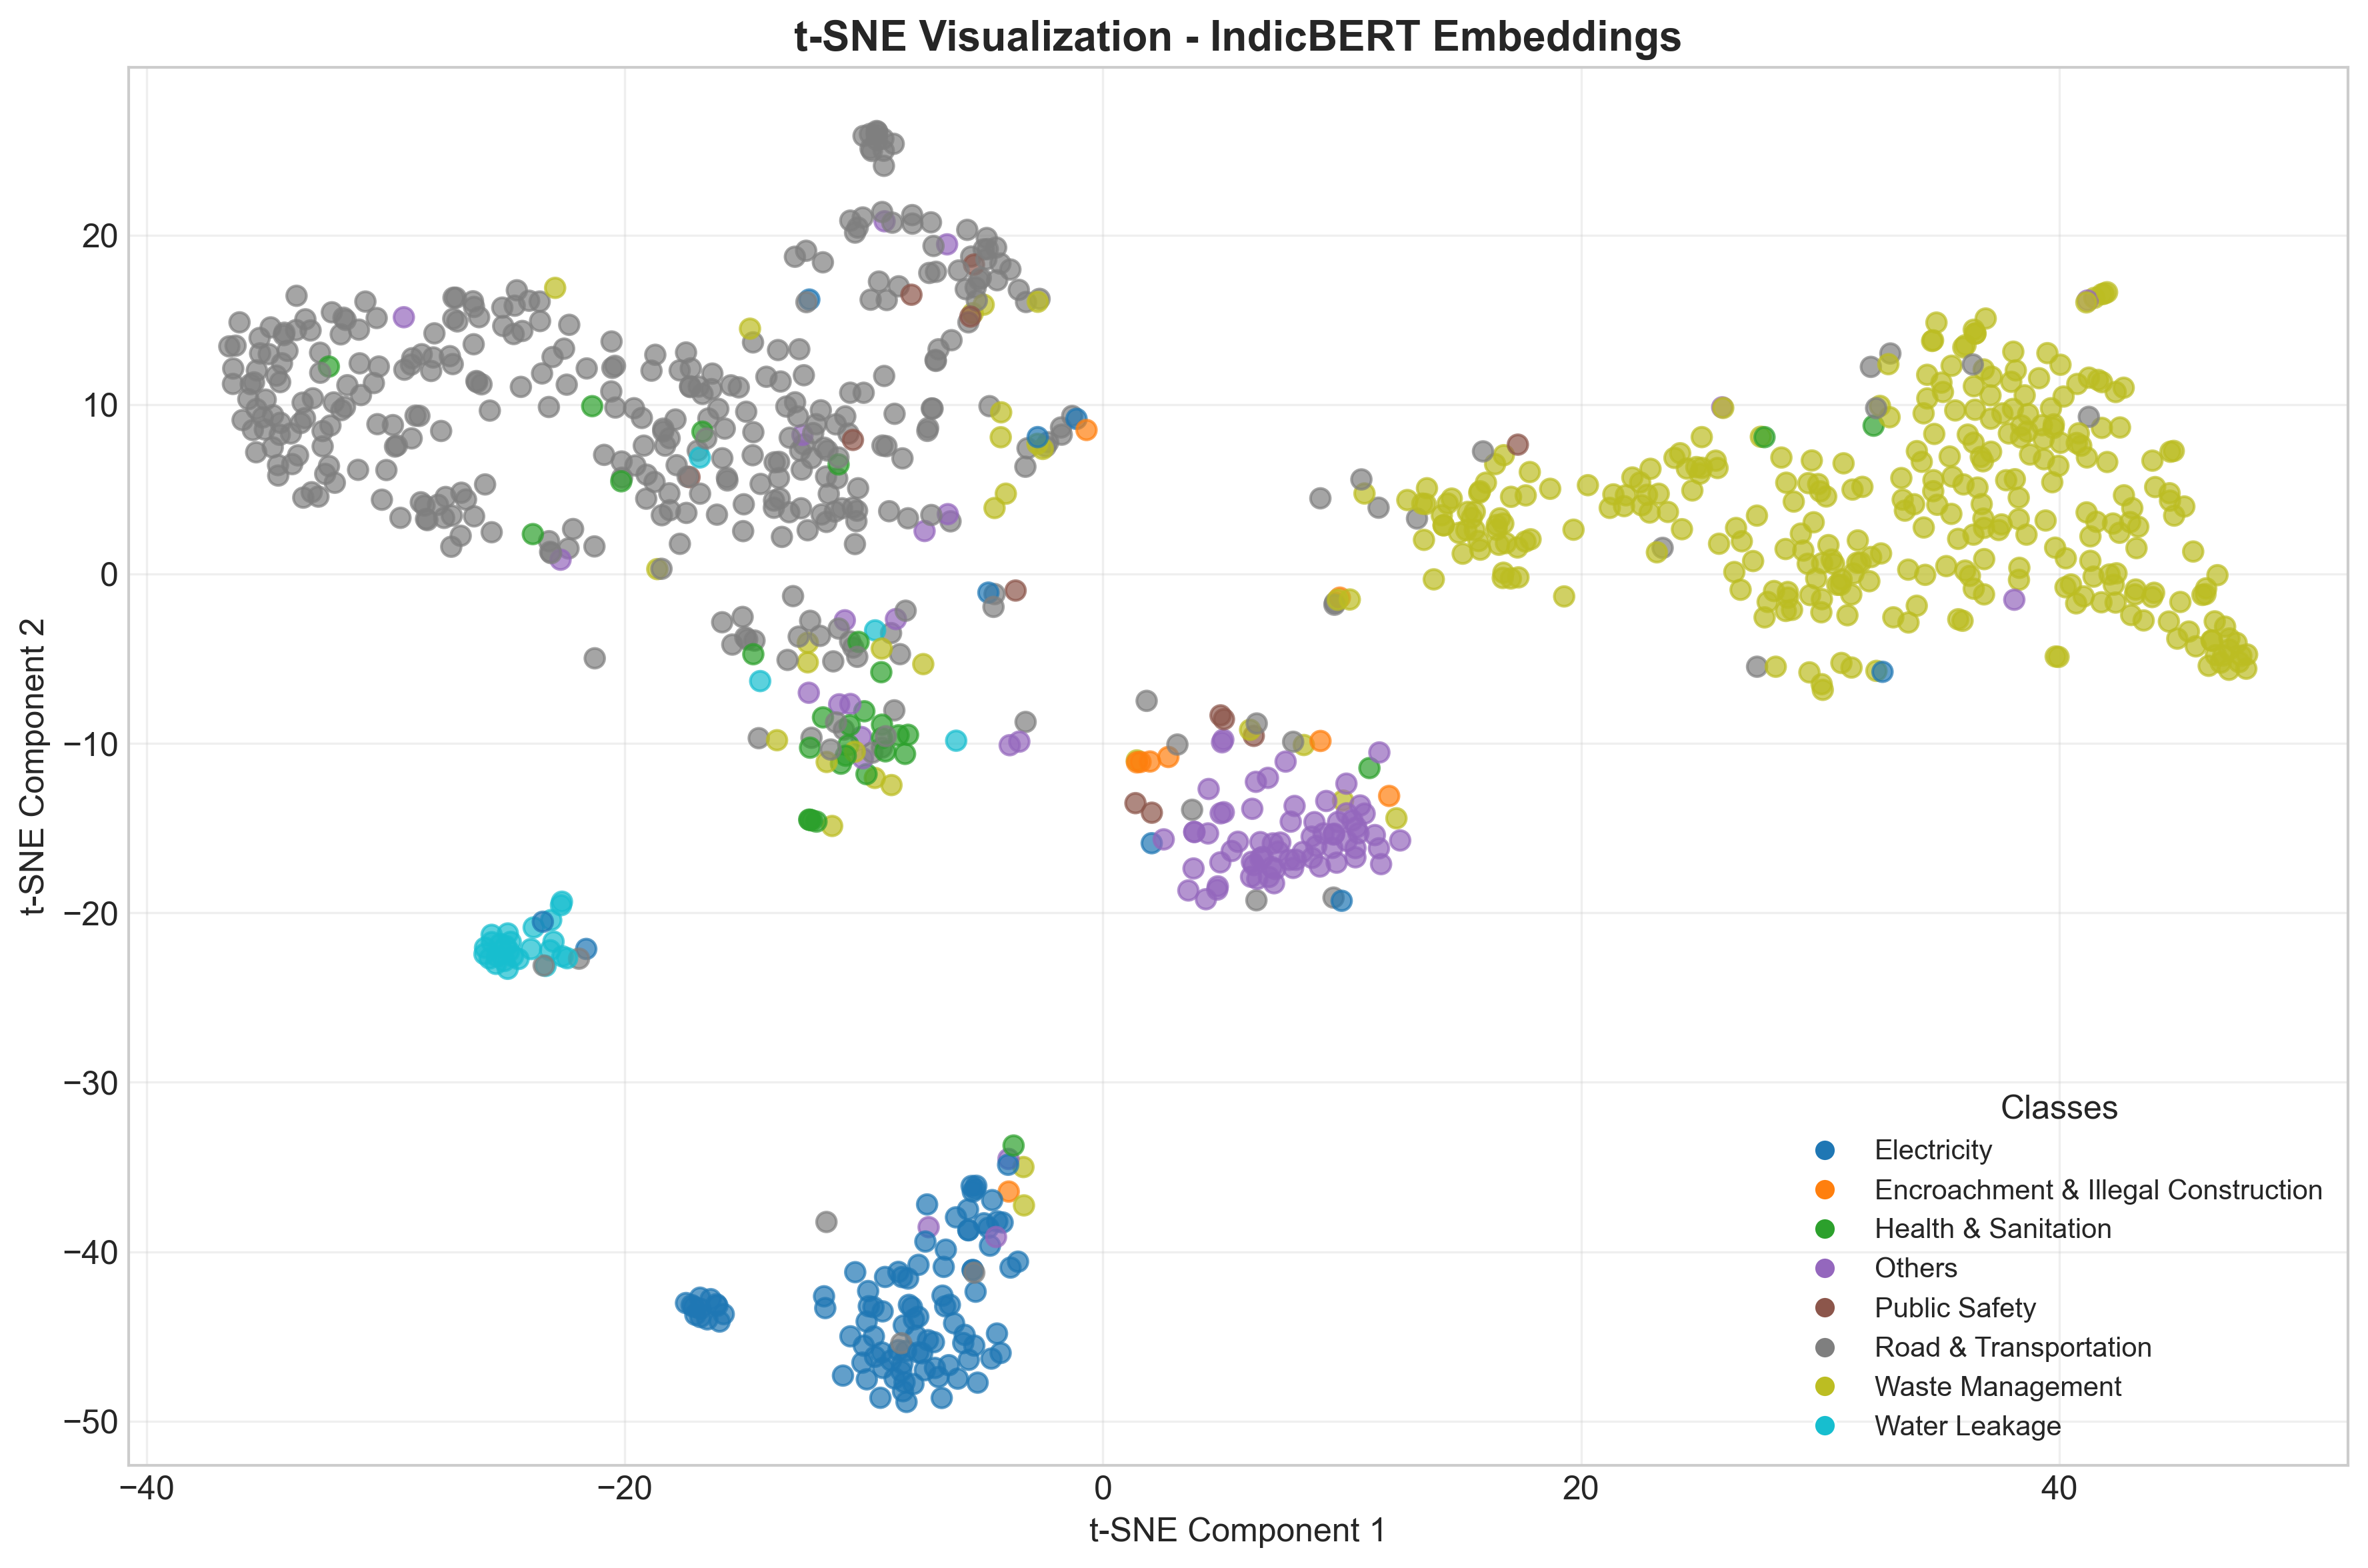

In [13]:
# ============================================================================
# CELL 12: VISUALIZATION - T-SNE EMBEDDINGS
# ============================================================================

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np


def plot_tsne_embeddings(embeddings, labels, label_names, title, save_path=None):
    """
    Create a 2D t-SNE visualization of IndicBERT embeddings.
    """

    print("Computing t-SNE embeddings...")

    embeddings = np.asarray(embeddings)
    labels = np.asarray(labels)

    # t-SNE dimensionality reduction
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        max_iter=1000,          # Updated parameter (replaces n_iter)
        random_state=Config.SEED,
        init="pca",
        learning_rate="auto"
    )

    embeddings_2d = tsne.fit_transform(embeddings)

    print(f"t-SNE completed. Output shape: {embeddings_2d.shape}")

    # ----------------------------------------------------------------------
    # Plot
    # ----------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 8))

    scatter = ax.scatter(
        embeddings_2d[:, 0],
        embeddings_2d[:, 1],
        c=labels,
        cmap="tab10",
        alpha=0.7,
        s=50
    )

    ax.set_title(f"t-SNE Visualization - {title}", fontsize=15, fontweight="bold")
    ax.set_xlabel("t-SNE Component 1")
    ax.set_ylabel("t-SNE Component 2")
    ax.grid(alpha=0.3)

    # Legend
    legend_elements = [
        plt.Line2D(
            [0], [0],
            marker="o",
            color="w",
            markerfacecolor=scatter.cmap(i / max(1, len(label_names) - 1)),
            markersize=8,
            label=name
        )
        for i, name in enumerate(label_names)
    ]

    ax.legend(handles=legend_elements, title="Classes", fontsize=10)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"t-SNE plot saved to: {save_path}")

    plt.show()
    plt.close()


# --------------------------------------------------------------------------
# Get embeddings and labels
# --------------------------------------------------------------------------

embeddings = evaluation_results["embeddings"]
labels = evaluation_results["labels"]["primary"]

# Sample if dataset is large
if len(embeddings) > 1000:
    np.random.seed(Config.SEED)
    idx = np.random.choice(len(embeddings), 1000, replace=False)
    embeddings = embeddings[idx]
    labels = np.asarray(labels)[idx]

# Generate visualization
plot_tsne_embeddings(
    embeddings,
    labels,
    le_primary.classes_,
    title="IndicBERT Embeddings",
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png"
)

Sentiment analysis plot saved to: visualizations/sentiment_severity_analysis.png


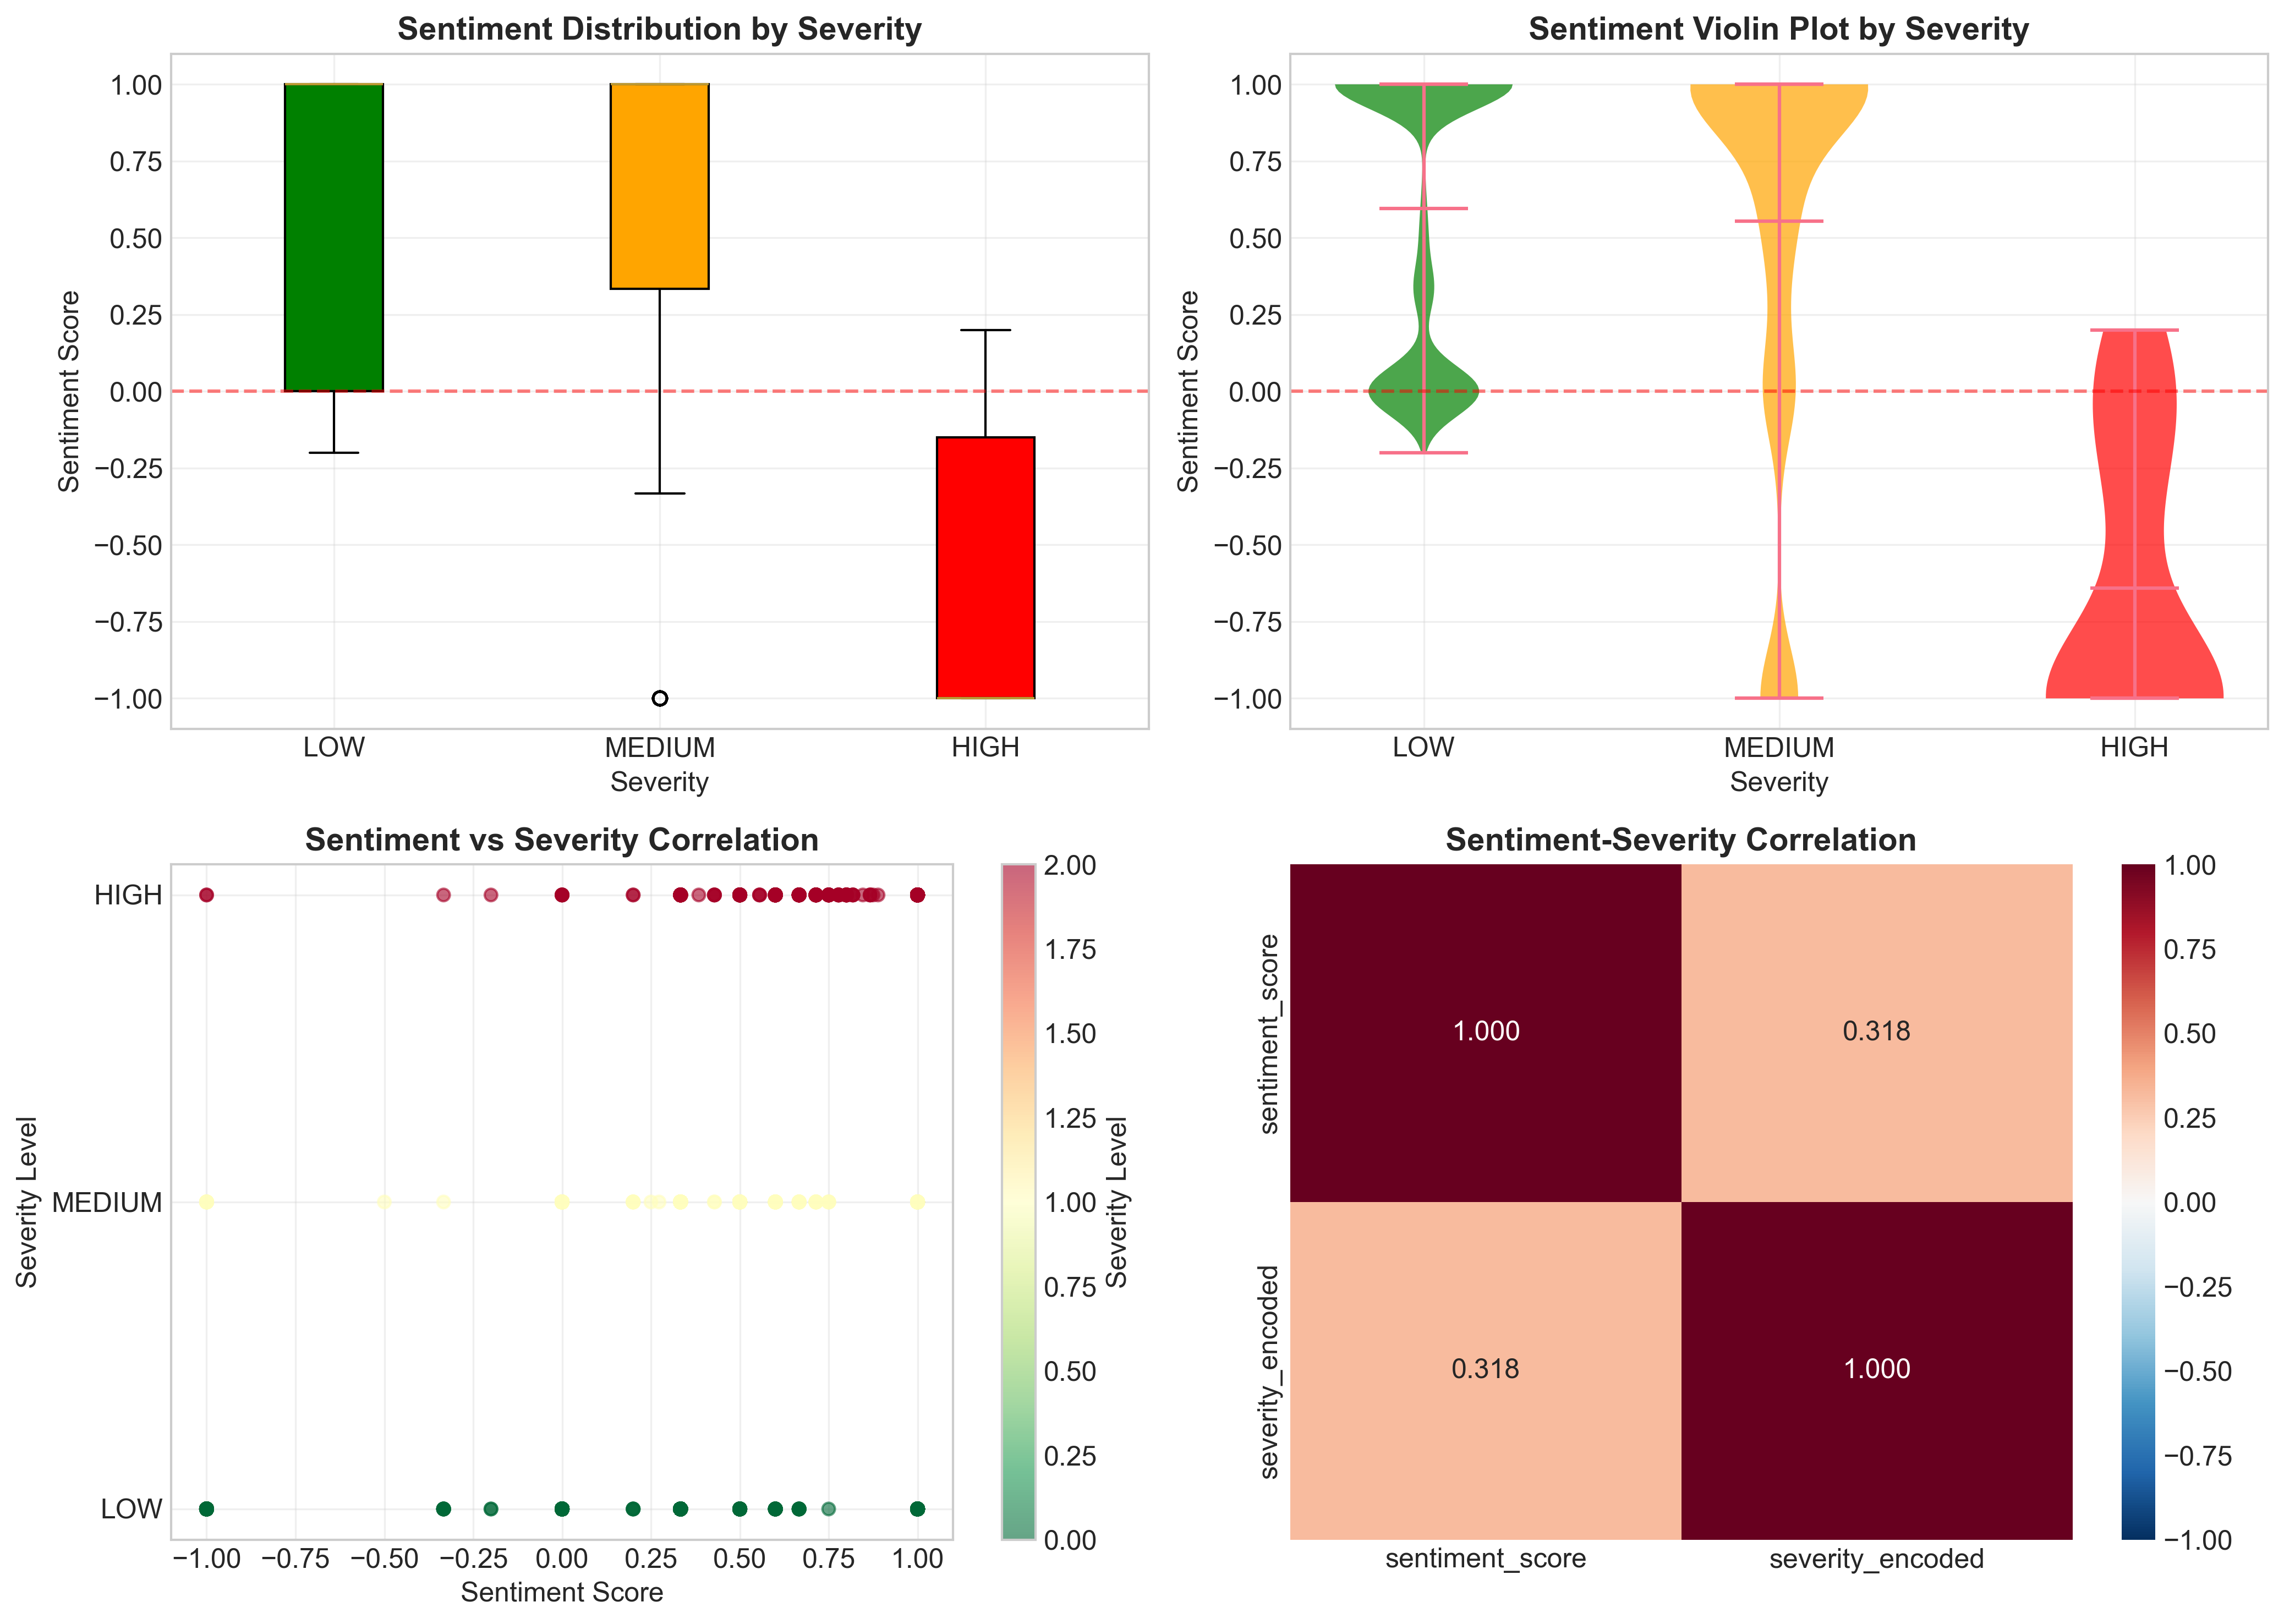

In [14]:
# ============================================================================
# CELL 13: VISUALIZATION - SENTIMENT VS SEVERITY ANALYSIS
# ============================================================================

def plot_sentiment_severity_analysis(df, save_path=None):
    """Analyze relationship between sentiment and severity"""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']
    
    # 1. Sentiment distribution by severity
    sentiment_by_severity = [
        df[df['enhanced_severity_label'] == s]['sentiment_score'].values 
        for s in severity_order
    ]
    
    # Box plot
    bp = axes[0, 0].boxplot(sentiment_by_severity, labels=severity_order, 
                           patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 0].set_xlabel('Severity', fontsize=12)
    axes[0, 0].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 0].set_title('Sentiment Distribution by Severity', fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Violin plot
    parts = axes[0, 1].violinplot(sentiment_by_severity, positions=range(len(severity_order)), 
                                 showmeans=True, showmedians=True)
    for i, pc in enumerate(parts['bodies']):
        pc.set_facecolor(colors[i])
        pc.set_alpha(0.7)
    axes[0, 1].set_xticks(range(len(severity_order)))
    axes[0, 1].set_xticklabels(severity_order)
    axes[0, 1].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 1].set_xlabel('Severity', fontsize=12)
    axes[0, 1].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 1].set_title('Sentiment Violin Plot by Severity', fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Scatter plot
    scatter = axes[1, 0].scatter(
        df['sentiment_score'], 
        df['severity_encoded'],
        c=df['severity_encoded'],
        cmap='RdYlGn_r',
        alpha=0.6,
        s=30
    )
    axes[1, 0].set_xlabel('Sentiment Score', fontsize=12)
    axes[1, 0].set_ylabel('Severity Level', fontsize=12)
    axes[1, 0].set_yticks([0, 1, 2])
    axes[1, 0].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
    axes[1, 0].set_title('Sentiment vs Severity Correlation', fontweight='bold')
    axes[1, 0].grid(True, alpha=0.3)
    plt.colorbar(scatter, label='Severity Level', ax=axes[1, 0])
    
    # 4. Correlation heatmap
    correlation_data = df[['sentiment_score', 'severity_encoded']].corr()
    sns.heatmap(correlation_data, annot=True, fmt='.3f', cmap='RdBu_r',
               center=0, vmin=-1, vmax=1, ax=axes[1, 1])
    axes[1, 1].set_title('Sentiment-Severity Correlation', fontweight='bold')
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Sentiment analysis plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Plot sentiment analysis
plot_sentiment_severity_analysis(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/sentiment_severity_analysis.png"
)

Class distribution plot saved to: visualizations/class_distribution.png


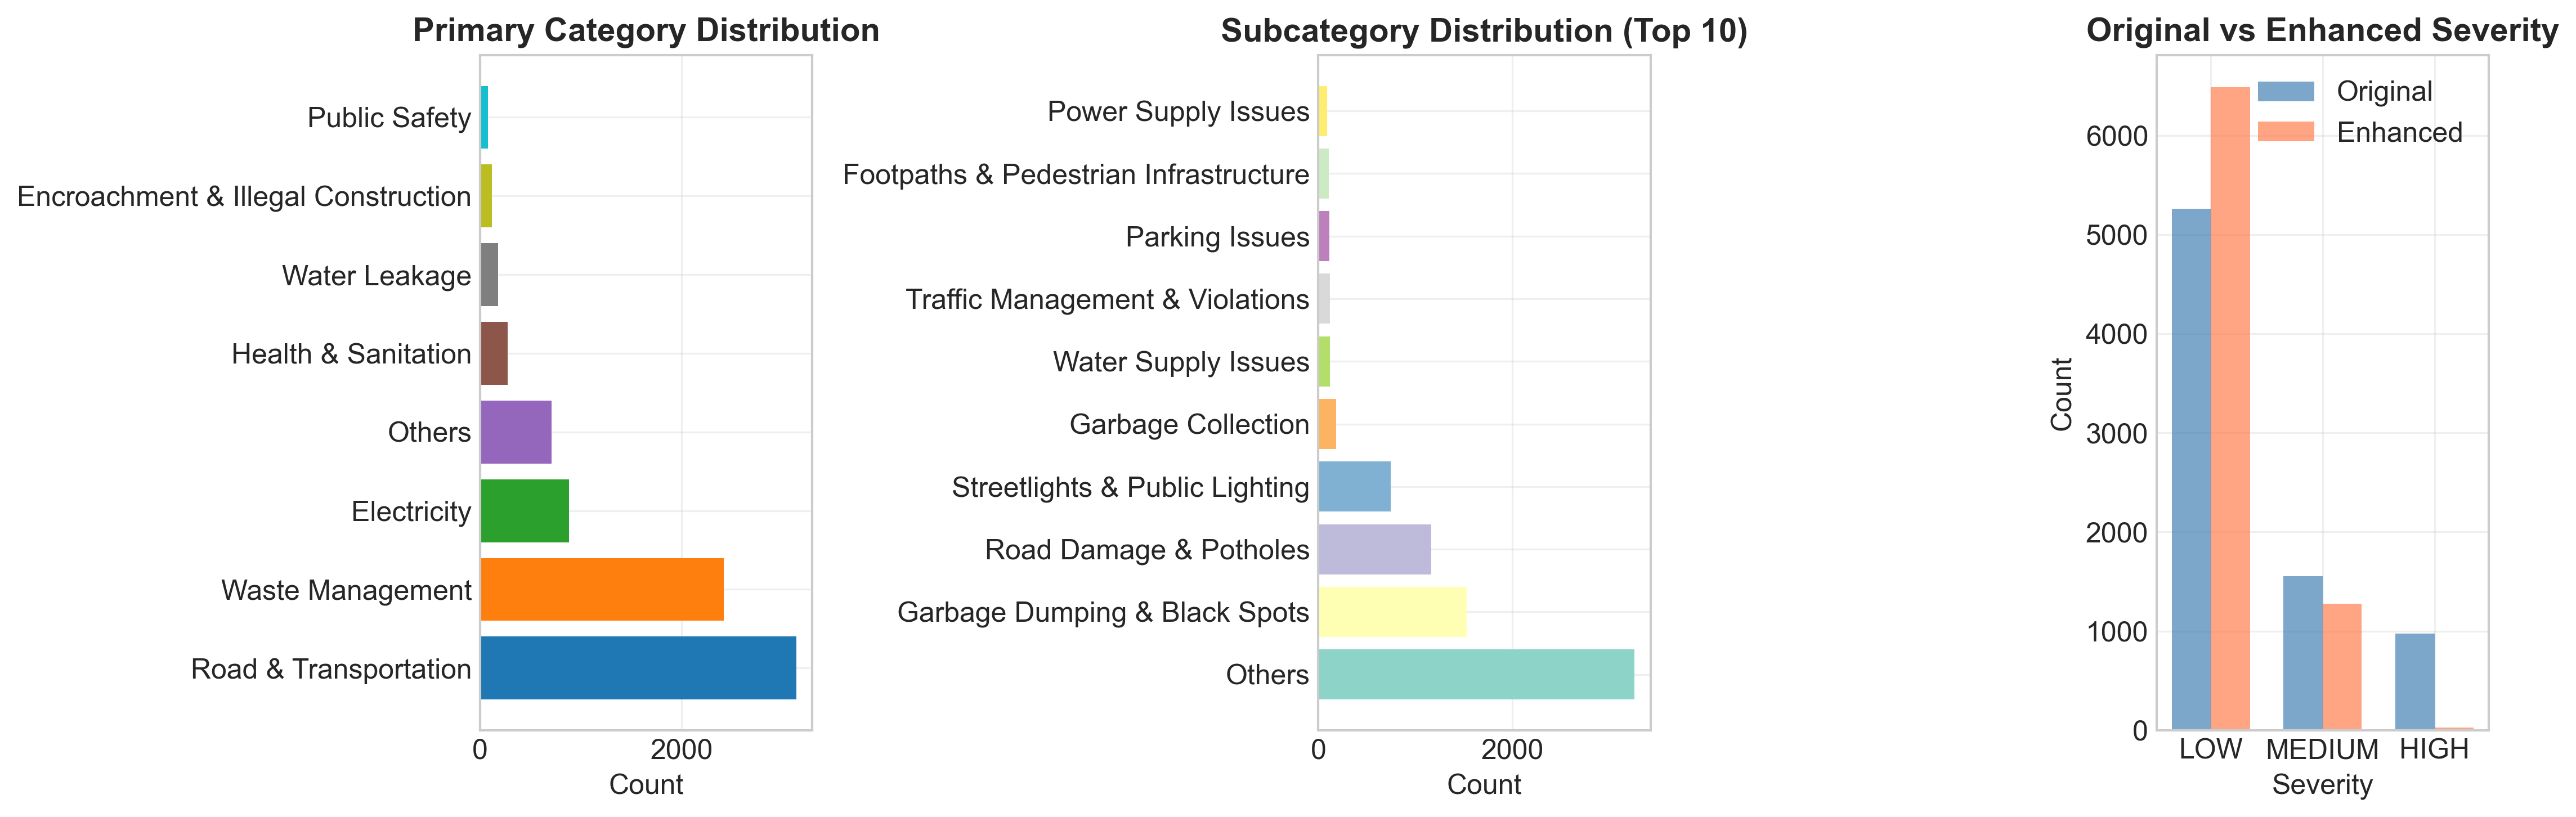

In [15]:
# ============================================================================
# CELL 14: VISUALIZATION - CLASS DISTRIBUTION
# ============================================================================

def plot_class_distribution(df, save_path=None):
    """Plot class distribution for all tasks"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 1. Primary category distribution
    primary_counts = df['category_primary'].value_counts()
    colors = plt.cm.tab10(np.linspace(0, 1, len(primary_counts)))
    axes[0].barh(primary_counts.index, primary_counts.values, color=colors)
    axes[0].set_xlabel('Count', fontsize=12)
    axes[0].set_title('Primary Category Distribution', fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    
    # 2. Subcategory distribution (top 10)
    subcat_counts = df['category_secondary'].value_counts().head(10)
    colors = plt.cm.Set3(np.linspace(0, 1, len(subcat_counts)))
    axes[1].barh(subcat_counts.index, subcat_counts.values, color=colors)
    axes[1].set_xlabel('Count', fontsize=12)
    axes[1].set_title('Subcategory Distribution (Top 10)', fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    # 3. Severity distribution (original vs enhanced)
    original_severity = df['severity'].value_counts()
    enhanced_severity = df['enhanced_severity_label'].value_counts()
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    original_counts = [original_severity.get(s, 0) for s in severity_order]
    enhanced_counts = [enhanced_severity.get(s, 0) for s in severity_order]
    
    x = np.arange(len(severity_order))
    width = 0.35
    
    bars1 = axes[2].bar(x - width/2, original_counts, width, label='Original', 
                       color='steelblue', alpha=0.7)
    bars2 = axes[2].bar(x + width/2, enhanced_counts, width, label='Enhanced',
                       color='coral', alpha=0.7)
    
    axes[2].set_xlabel('Severity', fontsize=12)
    axes[2].set_ylabel('Count', fontsize=12)
    axes[2].set_title('Original vs Enhanced Severity', fontweight='bold')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(severity_order)
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Class distribution plot saved to: {save_path}")
    
    plt.show()
    plt.close()

# Plot class distribution
plot_class_distribution(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/class_distribution.png"
)

In [17]:
# ============================================================================
# CELL 15: CLASSIFICATION REPORTS
# ============================================================================

def generate_classification_reports(evaluation_results, preprocessor):
    """Generate and print classification reports"""
    
    le_primary = preprocessor.le_primary
    le_subcat = preprocessor.le_subcat
    le_severity = preprocessor.le_severity
    
    # Primary task
    print("\n" + "="*70)
    print("CLASSIFICATION REPORT - PRIMARY CATEGORY")
    print("="*70)
    print(classification_report(
        evaluation_results['labels']['primary'],
        evaluation_results['predictions']['primary'],
        target_names=le_primary.classes_,
        digits=4
    ))
    
    # Subcategory task
    print("\n" + "="*70)
    print("CLASSIFICATION REPORT - SUBCATEGORY")
    print("="*70)
    print(classification_report(
    evaluation_results['labels']['subcat'],
    evaluation_results['predictions']['subcat'],
    labels=np.arange(len(le_subcat.classes_)),
    target_names=le_subcat.classes_,
    digits=4,
    zero_division=0
))
    
    # Severity task
    print("\n" + "="*70)
    print("CLASSIFICATION REPORT - SEVERITY")
    print("="*70)
    print(classification_report(
        evaluation_results['labels']['severity'],
        evaluation_results['predictions']['severity'],
        target_names=le_severity.classes_,
        digits=4
    ))

# Generate classification reports
generate_classification_reports(evaluation_results, preprocessor)


CLASSIFICATION REPORT - PRIMARY CATEGORY
                                     precision    recall  f1-score   support

                        Electricity     0.9405    0.9186    0.9294       172
Encroachment & Illegal Construction     0.5714    0.4706    0.5161        17
                Health & Sanitation     0.5224    0.6250    0.5691        56
                             Others     0.7823    0.7616    0.7718       151
                      Public Safety     0.6667    0.1818    0.2857        22
              Road & Transportation     0.8622    0.9048    0.8830       588
                   Waste Management     0.9308    0.9128    0.9217       516
                      Water Leakage     0.8500    0.7907    0.8193        43

                           accuracy                         0.8671      1565
                          macro avg     0.7658    0.6957    0.7120      1565
                       weighted avg     0.8673    0.8671    0.8648      1565


CLASSIFICATION REPORT - SUBCAT

In [18]:
# ============================================================================
# CELL 16: STATISTICAL VALIDATION
# ============================================================================

def perform_statistical_tests(evaluation_results, preprocessor):
    """Perform statistical tests on predictions"""
    
    print("\n" + "="*70)
    print("STATISTICAL VALIDATION")
    print("="*70)
    
    # 1. Confidence intervals for accuracy
    def calculate_confidence_interval(accuracy, n, confidence=0.95):
        """Calculate confidence interval for accuracy"""
        se = np.sqrt((accuracy * (1 - accuracy)) / n)
        z_score = 1.96  # 95% confidence
        ci_lower = accuracy - z_score * se
        ci_upper = accuracy + z_score * se
        return ci_lower, ci_upper
    
    n_test = len(test_df)
    
    print("\n1. Confidence Intervals (95%):")
    for task, metrics in evaluation_results['metrics'].items():
        acc = metrics['accuracy']
        ci_lower, ci_upper = calculate_confidence_interval(acc, n_test)
        print(f"  {task.capitalize()} Accuracy: {acc:.4f} ± {acc - ci_lower:.4f}")
        print(f"    CI: [{ci_lower:.4f}, {ci_upper:.4f}]")
    
    # 2. Per-class performance statistics
    print("\n2. Per-class Performance Statistics:")
    
    for task_name, labels_key in [('Primary', 'primary'), ('Subcategory', 'subcat'), ('Severity', 'severity')]:
        print(f"\n  {task_name}:")
        
        y_true = evaluation_results['labels'][labels_key]
        y_pred = evaluation_results['predictions'][labels_key]
        
        # Per-class metrics
        precision, recall, f1, support = precision_recall_fscore_support(
            y_true, y_pred, average=None
        )
        
        # Find best and worst performing classes
        f1_with_class = list(zip(f1, 
                                 preprocessor.le_primary.classes_ if labels_key == 'primary' 
                                 else preprocessor.le_subcat.classes_ if labels_key == 'subcat'
                                 else preprocessor.le_severity.classes_))
        f1_with_class.sort(reverse=True)
        
        print(f"    Best performing class: {f1_with_class[0][1]} (F1: {f1_with_class[0][0]:.4f})")
        print(f"    Worst performing class: {f1_with_class[-1][1]} (F1: {f1_with_class[-1][0]:.4f})")
        print(f"    Mean F1: {np.mean(f1):.4f} ± {np.std(f1):.4f}")
    
    # 3. Sentiment correlation
    print("\n3. Sentiment-Severity Correlation:")
    correlation = train_df['sentiment_score'].corr(train_df['severity_encoded'])
    print(f"  Pearson correlation: {correlation:.4f}")
    
    # Statistical significance of sentiment difference across severity levels
    severity_groups = [train_df[train_df['severity_encoded'] == i]['sentiment_score'] 
                      for i in range(3)]
    f_stat, p_val = f_oneway(*severity_groups)
    print(f"  ANOVA F-statistic: {f_stat:.4f}, p-value: {p_val:.4f}")
    
    if p_val < 0.05:
        print("  ✅ Significant difference in sentiment across severity levels")
    else:
        print("  ❌ No significant difference in sentiment across severity levels")
    
    # 4. Model stability
    print("\n4. Model Stability Analysis:")
    
    # Calculate metrics over epochs
    accuracy_values = trainer.history['val_accuracy']
    f1_values = trainer.history['val_f1']
    
    print(f"  Validation Accuracy: Mean={np.mean(accuracy_values):.4f} ± {np.std(accuracy_values):.4f}")
    print(f"  Validation F1-Score: Mean={np.mean(f1_values):.4f} ± {np.std(f1_values):.4f}")
    
    # Check for overfitting
    final_train_loss = trainer.history['train_loss'][-1]
    final_val_loss = trainer.history['val_loss'][-1]
    loss_ratio = final_val_loss / final_train_loss
    
    if loss_ratio < 1.2:
        print(f"  ✅ No significant overfitting (Loss ratio: {loss_ratio:.2f})")
    else:
        print(f"  ⚠️ Possible overfitting (Loss ratio: {loss_ratio:.2f})")

# Perform statistical tests
perform_statistical_tests(evaluation_results, preprocessor)


STATISTICAL VALIDATION

1. Confidence Intervals (95%):
  Primary Accuracy: 0.8671 ± 0.0168
    CI: [0.8503, 0.8839]
  Subcategory Accuracy: 0.7163 ± 0.0223
    CI: [0.6940, 0.7386]
  Severity Accuracy: 0.8556 ± 0.0174
    CI: [0.8382, 0.8730]

2. Per-class Performance Statistics:

  Primary:
    Best performing class: Electricity (F1: 0.9294)
    Worst performing class: Public Safety (F1: 0.2857)
    Mean F1: 0.7120 ± 0.2168

  Subcategory:
    Best performing class: Mosquito & Pest Control (F1: 0.9231)
    Worst performing class: Animal & Organic Waste (F1: 0.0000)
    Mean F1: 0.4092 ± 0.3333

  Severity:
    Best performing class: LOW (F1: 0.9183)
    Worst performing class: HIGH (F1: 0.0000)
    Mean F1: 0.4450 ± 0.3754

3. Sentiment-Severity Correlation:
  Pearson correlation: 0.3175
  ANOVA F-statistic: 460.3001, p-value: 0.0000
  ✅ Significant difference in sentiment across severity levels

4. Model Stability Analysis:
  Validation Accuracy: Mean=0.8491 ± 0.0104
  Validation F1

In [19]:
# ============================================================================
# CELL 17: INFERENCE FUNCTION
# ============================================================================

def predict_complaint(text, model, tokenizer, preprocessor, device):
    """
    Predict complaint category, subcategory, and severity
    
    Args:
        text: Input complaint text
        model: Trained model
        tokenizer: Tokenizer
        preprocessor: DataPreprocessor instance
        device: Device to run inference on
    
    Returns:
        Dictionary with predictions
    """
    # Compute sentiment
    sentiment = preprocessor.compute_sentiment_score(text)
    
    # Tokenize
    enc = tokenizer(
        text,
        truncation=True,
        padding="max_length",
        max_length=Config.MAX_LENGTH,
        return_tensors="pt"
    )
    
    input_ids = enc["input_ids"].to(device)
    attention_mask = enc["attention_mask"].to(device)
    sentiment_tensor = torch.tensor([sentiment], dtype=torch.float).to(device)
    
    # Predict
    model.eval()
    with torch.no_grad():
        p1, p2, p3 = model(input_ids, attention_mask, sentiment_tensor)
    
    # Convert predictions to labels
    primary = preprocessor.le_primary.inverse_transform(
        [torch.argmax(p1).item()]
    )[0]
    subcat = preprocessor.le_subcat.inverse_transform(
        [torch.argmax(p2).item()]
    )[0]
    severity = preprocessor.le_severity.inverse_transform(
        [torch.argmax(p3).item()]
    )[0]
    
    # Get confidence scores
    primary_conf = torch.softmax(p1, dim=1).max().item()
    subcat_conf = torch.softmax(p2, dim=1).max().item()
    severity_conf = torch.softmax(p3, dim=1).max().item()
    
    return {
        'primary_category': primary,
        'subcategory': subcat,
        'severity': severity,
        'sentiment_score': sentiment,
        'confidence': {
            'primary': primary_conf,
            'subcategory': subcat_conf,
            'severity': severity_conf
        }
    }

# Test inference
test_texts = [
    "Garbage not collected in my area for last 5 days. Bad smell everywhere! Very urgent!",
    "There is a very big pothole on the main road, my car got damaged",
    "Water leakage in our building, please fix immediately, it's an emergency!",
    "Thank you for fixing the streetlight in our area, it's working now.",
    "Streetlights not working on my street for 3 days, very dangerous at night",
    "The garbage bins are overflowing and spreading foul smell in the entire colony"
]

print("\n" + "="*70)
print("INFERENCE DEMO")
print("="*70)

for i, text in enumerate(test_texts, 1):
    print(f"\nText {i}: {text}")
    print("-" * 50)
    
    result = predict_complaint(
        text, model, tokenizer, preprocessor, Config.DEVICE
    )
    
    print(f"Primary Category: {result['primary_category']}")
    print(f"Subcategory: {result['subcategory']}")
    print(f"Severity: {result['severity']}")
    print(f"Sentiment Score: {result['sentiment_score']:.3f}")
    print(f"Confidence:")
    print(f"  Primary: {result['confidence']['primary']:.4f}")
    print(f"  Subcategory: {result['confidence']['subcategory']:.4f}")
    print(f"  Severity: {result['confidence']['severity']:.4f}")


INFERENCE DEMO

Text 1: Garbage not collected in my area for last 5 days. Bad smell everywhere! Very urgent!
--------------------------------------------------
Primary Category: Waste Management
Subcategory: Garbage Collection
Severity: LOW
Sentiment Score: 1.000
Confidence:
  Primary: 0.9917
  Subcategory: 0.5263
  Severity: 0.9827

Text 2: There is a very big pothole on the main road, my car got damaged
--------------------------------------------------
Primary Category: Road & Transportation
Subcategory: Road Damage & Potholes
Severity: LOW
Sentiment Score: 1.000
Confidence:
  Primary: 0.9901
  Subcategory: 0.8558
  Severity: 0.9749

Text 3: Water leakage in our building, please fix immediately, it's an emergency!
--------------------------------------------------
Primary Category: Water Leakage
Subcategory: Water Supply Issues
Severity: LOW
Sentiment Score: 1.000
Confidence:
  Primary: 0.8474
  Subcategory: 0.3057
  Severity: 0.9678

Text 4: Thank you for fixing the streetlight in

In [20]:
# ============================================================================
# CELL 18: SUMMARY REPORT
# ============================================================================

def generate_summary_report(model, evaluation_results, preprocessor, trainer):
    """Generate comprehensive summary report"""
    
    print("\n" + "="*70)
    print("INDICBERT MULTI-TASK COMPLAINT CLASSIFICATION - SUMMARY REPORT")
    print("="*70)
    
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.INDICBERT_PATH}")
    print(f"   Hidden Size: {base_model.config.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    print("\n3. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Optimizer: AdamW")
    print(f"   Device: {Config.DEVICE}")
    
    print("\n4. PERFORMANCE METRICS (Test Set):")
    for task, metrics in evaluation_results['metrics'].items():
        print(f"\n   {task.upper()}:")
        for metric_name, value in metrics.items():
            print(f"     {metric_name}: {value:.4f}")
    
    print("\n5. SENTIMENT ENHANCEMENT:")
    print(f"   Sentiment-Severity Correlation: {train_df['sentiment_score'].corr(train_df['severity_encoded']):.4f}")
    
    # Sentiment distribution
    severity_counts = train_df['enhanced_severity'].value_counts()
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        count = severity_counts.get(severity, 0)
        pct = (count / len(train_df)) * 100
        print(f"   {severity}: {count} ({pct:.1f}%)")
    
    print("\n6. MODEL STABILITY:")
    print(f"   Final Train Loss: {trainer.history['train_loss'][-1]:.4f}")
    print(f"   Final Val Loss: {trainer.history['val_loss'][-1]:.4f}")
    print(f"   Best Val Accuracy: {max(trainer.history['val_accuracy']):.4f}")
    print(f"   Best Val F1-Score: {max(trainer.history['val_f1']):.4f}")
    
    print("\n7. VISUALIZATIONS SAVED:")
    print(f"   - Training History: {Config.VISUALIZATION_DIR}/training_history.png")
    print(f"   - Confusion Matrices: {Config.VISUALIZATION_DIR}/confusion_*.png")
    print(f"   - t-SNE Embeddings: {Config.VISUALIZATION_DIR}/tsne_embeddings.png")
    print(f"   - Sentiment Analysis: {Config.VISUALIZATION_DIR}/sentiment_severity_analysis.png")
    print(f"   - Class Distribution: {Config.VISUALIZATION_DIR}/class_distribution.png")
    
    print("\n8. SAVED FILES:")
    print(f"   - Model: {Config.MODEL_DIR}/indicbert_multitask_model.pt")
    print(f"   - Encoders: {Config.MODEL_DIR}/le_*.pkl")
    
    print("\n" + "="*70)
    print("END OF REPORT")
    print("="*70)

# Generate summary report
generate_summary_report(
    model, evaluation_results, preprocessor, trainer
)


INDICBERT MULTI-TASK COMPLAINT CLASSIFICATION - SUMMARY REPORT

1. DATASET STATISTICS:
   Training samples: 7791
   Validation samples: 1555
   Test samples: 1565
   Primary categories: 8
   Subcategories: 30
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: ai4bharat/indic-bert
   Hidden Size: 768
   Total Parameters: 33,475,116
   Dropout Rate: 0.3
   Max Sequence Length: 128

3. TRAINING DETAILS:
   Epochs: 10
   Batch Size: 16
   Learning Rate: 2e-05
   Optimizer: AdamW
   Device: cuda

4. PERFORMANCE METRICS (Test Set):

   PRIMARY:
     accuracy: 0.8671
     precision: 0.8673
     recall: 0.8671
     f1: 0.8648

   SUBCATEGORY:
     accuracy: 0.7163
     precision: 0.7005
     recall: 0.7163
     f1: 0.7037

   SEVERITY:
     accuracy: 0.8556
     precision: 0.8356
     recall: 0.8556
     f1: 0.8304

5. SENTIMENT ENHANCEMENT:
   Sentiment-Severity Correlation: 0.3175
   LOW: 0 (0.0%)
   MEDIUM: 0 (0.0%)
   HIGH: 0 (0.0%)

6. MODEL STABILITY:
   Final Train Loss: 0.47

In [22]:
# ============================================================================
# CELL 19: SAVE RESULTS FOR PUBLICATION
# ============================================================================

def save_publication_results(evaluation_results, preprocessor, trainer, save_dir):
    """Save results in format suitable for publication tables"""
    
    print("\nSaving results for publication...")
    
    # 1. Save metrics as CSV
    metrics_df = pd.DataFrame()
    
    for task, metrics in evaluation_results['metrics'].items():
        row = pd.DataFrame([metrics], index=[task])
        metrics_df = pd.concat([metrics_df, row])
    
    metrics_df.to_csv(f"{save_dir}/test_metrics.csv")
    print(f"Metrics saved to: {save_dir}/test_metrics.csv")
    
    # 2. Save training history
    history_df = pd.DataFrame(trainer.history)
    history_df.to_csv(f"{save_dir}/training_history.csv")
    print(f"Training history saved to: {save_dir}/training_history.csv")
    
    # 3. Save predictions
    predictions_df = pd.DataFrame({
        'true_primary': evaluation_results['labels']['primary'],
        'pred_primary': evaluation_results['predictions']['primary'],
        'true_subcat': evaluation_results['labels']['subcat'],
        'pred_subcat': evaluation_results['predictions']['subcat'],
        'true_severity': evaluation_results['labels']['severity'],
        'pred_severity': evaluation_results['predictions']['severity']
    })
    predictions_df.to_csv(f"{save_dir}/test_predictions.csv")
    print(f"Predictions saved to: {save_dir}/test_predictions.csv")
    
    # 4. Save classification reports
    with open(f"{save_dir}/classification_report.txt", 'w') as f:
        f.write("CLASSIFICATION REPORTS\n")
        f.write("="*70 + "\n\n")
        
        # Primary
        f.write("PRIMARY CATEGORY\n")
        f.write("-"*50 + "\n")
        f.write(classification_report(
            evaluation_results['labels']['primary'],
            evaluation_results['predictions']['primary'],
            target_names=preprocessor.le_primary.classes_
        ))
        f.write("\n\n")
        
        # Subcategory
        f.write("SUBCATEGORY\n")
        f.write("-"*50 + "\n")
        f.write(classification_report(
    evaluation_results['labels']['subcat'],
    evaluation_results['predictions']['subcat'],
    labels=np.arange(len(le_subcat.classes_)),
    target_names=le_subcat.classes_,
    digits=4,
    zero_division=0
))
        f.write("\n\n")
        
        # Severity
        f.write("SEVERITY\n")
        f.write("-"*50 + "\n")
        f.write(classification_report(
            evaluation_results['labels']['severity'],
            evaluation_results['predictions']['severity'],
            target_names=preprocessor.le_severity.classes_
        ))
    
    print(f"Classification reports saved to: {save_dir}/classification_report.txt")
    
    print("\n✅ All publication results saved successfully")

# Save results
save_publication_results(
    evaluation_results, 
    preprocessor, 
    trainer,
    Config.OUTPUT_DIR
)


Saving results for publication...
Metrics saved to: results/test_metrics.csv
Training history saved to: results/training_history.csv
Predictions saved to: results/test_predictions.csv
Classification reports saved to: results/classification_report.txt

✅ All publication results saved successfully


In [23]:
# ============================================================================
# IEEE ACCESS PAPER: IndicBERT Multi-Task Classification for Citizen Complaints
# with Imbalanced Dataset Handling
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
from datetime import datetime

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

import random
set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION
# ============================================================================

class Config:
    """Configuration settings for IndicBERT training with imbalance handling"""
    
    # Model paths
    INDICBERT_PATH = "ai4bharat/indic-bert"
    
    # Training params
    MAX_LENGTH = 128
    BATCH_SIZE = 16
    EPOCHS = 15
    LEARNING_RATE = 2e-5
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 2
    WARMUP_RATIO = 0.1
    
    # Imbalance handling
    USE_CLASS_WEIGHTS = True
    USE_FOCAL_LOSS = True
    USE_WEIGHTED_SAMPLER = True
    FOCAL_ALPHA = 0.25
    FOCAL_GAMMA = 2.0
    
    # Data paths
    DATA_DIR = "dataset"
    TRAIN_PATH = f"{DATA_DIR}/train/train.csv"
    DEV_PATH = f"{DATA_DIR}/dev/dev.csv"
    TEST_PATH = f"{DATA_DIR}/test/test.csv"
    
    # Output directories
    BASE_DIR = "indicbert_results"
    MODEL_DIR = f"{BASE_DIR}/models"
    VISUALIZATION_DIR = f"{BASE_DIR}/visualizations"
    LOG_DIR = f"{BASE_DIR}/logs"
    RESULTS_DIR = f"{BASE_DIR}/results"
    
    # Create directories
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR, RESULTS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Random seed
    SEED = 42
    
    # HuggingFace token (replace with your token)
    HF_TOKEN = os.getenv("HF_TOKEN")

print(f"Configuration loaded successfully")
print(f"Results will be saved to: {Config.BASE_DIR}")
print(f"Imbalance Handling:")
print(f"  Class Weights: {Config.USE_CLASS_WEIGHTS}")
print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
print(f"  Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")

Configuration loaded successfully
Results will be saved to: indicbert_results
Imbalance Handling:
  Class Weights: True
  Focal Loss: True
  Weighted Sampler: True


In [25]:
# ============================================================================
# CELL 3: DATA LOADING WITH IMBALANCE ANALYSIS
# ============================================================================

class DataLoaderWithImbalance:
    """Load data and analyze class imbalance"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
        self.class_weights = {}
        
    def load_data(self):
        """Load train, dev, test datasets"""
        print("Loading datasets...")
        
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(self.train_df)}")
        print(f"Dev samples: {len(self.dev_df)}")
        print(f"Test samples: {len(self.test_df)}")
        
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_imbalance(self, df, label_col, title=""):
        """Analyze and visualize class imbalance"""
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        
        print(f"\n{'='*60}")
        print(f"Class Distribution Analysis - {title}")
        print(f"{'='*60}")
        
        # Print statistics
        for cls, count in class_counts.items():
            pct = class_percentages[cls]
            print(f"  {cls}: {count} samples ({pct:.2f}%)")
        
        # Calculate imbalance metrics
        max_count = class_counts.max()
        min_count = class_counts.min()
        imbalance_ratio = max_count / min_count if min_count > 0 else float('inf')
        
        print(f"\nImbalance Metrics:")
        print(f"  Total classes: {len(class_counts)}")
        print(f"  Majority class size: {max_count}")
        print(f"  Minority class size: {min_count}")
        print(f"  Imbalance ratio: {imbalance_ratio:.2f}:1")
        
        return class_counts, class_percentages
    
    def compute_class_weights(self, df, label_col):
        """Compute class weights for balanced training"""
        class_labels = df[label_col].unique()
        class_weights = compute_class_weight(
            class_weight='balanced',
            classes=class_labels,
            y=df[label_col]
        )
        
        weight_dict = {cls: weight for cls, weight in zip(class_labels, class_weights)}
        
        print(f"\nClass Weights ({label_col}):")
        for cls, weight in weight_dict.items():
            print(f"  {cls}: {weight:.4f}")
        
        return weight_dict
    
    def create_weighted_sampler(self, df, label_col):
        """Create WeightedRandomSampler for balanced batch sampling"""
        labels = df[label_col].values
        class_counts = np.bincount(labels)
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[labels]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        return sampler
    
    def analyze_all(self):
        """Complete imbalance analysis on all datasets"""
        self.load_data()
        
        print("\n" + "="*80)
        print("COMPLETE IMBALANCE ANALYSIS")
        print("="*80)
        
        # Analyze primary categories
        self.analyze_imbalance(self.train_df, 'category_primary', 'Primary Categories (Train)')
        
        # Analyze secondary categories
        self.analyze_imbalance(self.train_df, 'category_secondary', 'Secondary Categories (Train)')
        
        # Analyze severity
        self.analyze_imbalance(self.train_df, 'severity', 'Severity (Train)')
        
        return self.train_df, self.dev_df, self.test_df

# Initialize and analyze
data_loader = DataLoaderWithImbalance()
train_df, dev_df, test_df = data_loader.load_data()

# Analyze imbalance
data_loader.analyze_all()

print("\n✅ Data loaded and imbalance analysis completed")

Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556
Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556

COMPLETE IMBALANCE ANALYSIS

Class Distribution Analysis - Primary Categories (Train)
  Road & Transportation: 4936 samples (39.68%)
  Waste Management: 3917 samples (31.48%)
  Electricity: 1393 samples (11.20%)
  Others: 1167 samples (9.38%)
  Health & Sanitation: 439 samples (3.53%)
  Water Leakage: 270 samples (2.17%)
  Encroachment & Illegal Construction: 189 samples (1.52%)
  Public Safety: 130 samples (1.04%)

Imbalance Metrics:
  Total classes: 8
  Majority class size: 4936
  Minority class size: 130
  Imbalance ratio: 37.97:1

Class Distribution Analysis - Secondary Categories (Train)
  Others: 5236 samples (42.09%)
  Garbage Dumping & Black Spots: 2495 samples (20.05%)
  Road Damage & Potholes: 1801 samples (14.48%)
  Streetlights & Public Lighting: 1162 samples (9.34%)
  Garbage Collection: 292 samples (2.35%)
  Water Sup

In [26]:
# ============================================================================
# CELL 4: DATA PREPROCESSING WITH SENTIMENT ANALYSIS
# ============================================================================

class DataPreprocessor:
    """Data preprocessing with sentiment analysis for severity enhancement"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
        df["text"] = (
            df["complaint_title"].astype(str) + " " +
            df["text_en"].astype(str) + " " +
            df["Hindi"].astype(str) + " " +
            df["Hinglish"].astype(str)
        )
        
        df = df.dropna(subset=["text", "category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def compute_sentiment_score(self, text):
        """Compute sentiment score for severity enhancement"""
        negative_words = {
            'emergency': 3, 'urgent': 3, 'critical': 3, 'immediately': 2,
            'asap': 2, 'urgently': 2, 'serious': 2, 'severe': 2,
            'dangerous': 2, 'threat': 2, 'risk': 2, 'panic': 2,
            'crisis': 3, 'problem': 1, 'issue': 1, 'complaint': 1,
            'not working': 2, 'broken': 2, 'damage': 2, 'accident': 2,
            'hurt': 2, 'injured': 2, 'unsafe': 2, 'hazard': 2,
            'frustrated': 1, 'angry': 1, 'disgusting': 1, 'terrible': 1,
            'worst': 1, 'bad': 1, 'awful': 1, 'horrible': 1,
            'stuck': 1, 'trapped': 1, 'blocked': 1, 'flood': 2,
            'leakage': 2, 'overflow': 2, 'smell': 1, 'stink': 1,
            'rotten': 1, 'garbage': 1, 'waste': 1, 'unhygienic': 1,
            'pothole': 1, 'crack': 1, 'uneven': 1, 'danger': 2
        }
        
        positive_words = {
            'good': 1, 'great': 1, 'excellent': 2, 'satisfied': 2,
            'happy': 1, 'thankful': 1, 'grateful': 1, 'appreciate': 1,
            'well': 1, 'nice': 1, 'better': 1, 'improved': 1,
            'fixed': 1, 'resolved': 1, 'working': 1, 'fine': 1
        }
        
        text_lower = str(text).lower()
        
        negative_score = sum(weight for word, weight in negative_words.items() 
                           if word in text_lower)
        positive_score = sum(weight for word, weight in positive_words.items() 
                           if word in text_lower)
        
        total_score = negative_score + positive_score
        if total_score == 0:
            return 0.0
        
        sentiment = (negative_score - positive_score) / max(total_score, 1)
        return np.clip(sentiment, -1, 1)
    
    def enhance_severity(self, df):
        """Enhance severity labels using sentiment analysis"""
        print("Computing sentiment scores...")
        df['sentiment_score'] = df['text'].apply(self.compute_sentiment_score)
        
        severity_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
        df['severity_encoded'] = df['severity'].map(severity_mapping)
        
        def adjust_severity(row):
            sentiment = row['sentiment_score']
            base_severity = row['severity_encoded']
            
            if sentiment > 0.3:
                adjustment = -1 if base_severity > 0 else 0
            elif sentiment < -0.3:
                adjustment = 1 if base_severity < 2 else 0
            else:
                adjustment = 0
            
            return min(2, max(0, base_severity + adjustment))
        
        df['enhanced_severity'] = df.apply(adjust_severity, axis=1)
        reverse_mapping = {0: 'LOW', 1: 'MEDIUM', 2: 'HIGH'}
        df['enhanced_severity_label'] = df['enhanced_severity'].map(reverse_mapping)
        
        return df
    
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("Preparing labels...")
        
        # Fit encoders on training data
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['enhanced_severity_label'])
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform all datasets
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["enhanced_severity_label"])
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        """Complete data processing pipeline"""
        # Preprocess text
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Enhance severity with sentiment
        train_df = self.enhance_severity(train_df)
        dev_df = self.enhance_severity(dev_df)
        test_df = self.enhance_severity(test_df)
        
        # Prepare labels
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"Final train samples: {len(train_df)}")
        print(f"Final dev samples: {len(dev_df)}")
        print(f"Final test samples: {len(test_df)}")
        
        return train_df, dev_df, test_df

# Process data
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)

print("\n✅ Data preprocessing completed successfully")

Preprocessing text...
Computing sentiment scores...
Computing sentiment scores...
Computing sentiment scores...
Preparing labels...
Primary categories: 8
Subcategories: 27
Severity levels: 3
Final train samples: 12441
Final dev samples: 1555
Final test samples: 1556

✅ Data preprocessing completed successfully


In [27]:
# ============================================================================
# CELL 5: DATASET WITH IMBALANCE HANDLING
# ============================================================================

class ComplaintDataset(Dataset):
    """Custom dataset for complaint classification with imbalance support"""
    
    def __init__(self, df, tokenizer, max_length=128, use_sentiment=True):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = df["sentiment_score"].tolist() if use_sentiment else [0.0] * len(df)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.use_sentiment = use_sentiment
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        features = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
        }
        
        if self.use_sentiment:
            features["sentiment"] = torch.tensor(self.sentiment[idx], dtype=torch.float)
        
        return features

def create_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with imbalance handling"""
    print("Creating datasets and dataloaders with imbalance handling...")
    
    # Create datasets
    train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    
    # Create weighted sampler for training
    if Config.USE_WEIGHTED_SAMPLER:
        print("Using WeightedRandomSampler for balanced batches...")
        class_counts = train_df['primary_label'].value_counts().sort_index().values
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[train_df['primary_label'].values]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        train_loader = DataLoader(
            train_dataset, 
            batch_size=Config.BATCH_SIZE, 
            sampler=sampler,
            num_workers=0,
            pin_memory=True
        )
    else:
        train_loader = DataLoader(
            train_dataset, 
            batch_size=Config.BATCH_SIZE, 
            shuffle=True,
            num_workers=0,
            pin_memory=True
        )
    
    # Dev and test loaders
    dev_loader = DataLoader(
        dev_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    test_loader = DataLoader(
        test_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    
    print(f"Train batches: {len(train_loader)}")
    print(f"Dev batches: {len(dev_loader)}")
    print(f"Test batches: {len(test_loader)}")
    
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined successfully")

✅ Dataset class defined successfully


In [28]:
# ============================================================================
# CELL 6: FOCAL LOSS FOR IMBALANCE HANDLING
# ============================================================================

class FocalLoss(nn.Module):
    """
    Focal Loss for handling class imbalance
    Focuses training on hard-to-classify examples
    """
    
    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        
    def forward(self, logits, targets):
        # Compute cross-entropy loss
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        
        # Compute pt (probability of correct class)
        pt = torch.exp(-ce_loss)
        
        # Compute focal loss
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

class MultiTaskLoss(nn.Module):
    """
    Multi-task loss with options for focal loss and class weights
    """
    
    def __init__(self, use_focal=True, alpha=0.25, gamma=2.0):
        super().__init__()
        self.use_focal = use_focal
        
        if use_focal:
            self.primary_loss = FocalLoss(alpha, gamma)
            self.subcat_loss = FocalLoss(alpha, gamma)
            self.severity_loss = FocalLoss(alpha, gamma)
        else:
            self.primary_loss = nn.CrossEntropyLoss()
            self.subcat_loss = nn.CrossEntropyLoss()
            self.severity_loss = nn.CrossEntropyLoss()
        
        # Weighted loss components
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
        
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total_loss = (self.primary_weight * loss1 + 
                      self.subcat_weight * loss2 + 
                      self.severity_weight * loss3)
        
        return total_loss, {
            'primary': loss1.item(),
            'subcat': loss2.item(),
            'severity': loss3.item(),
            'total': total_loss.item()
        }

# Initialize loss function
criterion = MultiTaskLoss(
    use_focal=Config.USE_FOCAL_LOSS,
    alpha=Config.FOCAL_ALPHA,
    gamma=Config.FOCAL_GAMMA
)

print(f"✅ Loss function initialized")
print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
if Config.USE_FOCAL_LOSS:
    print(f"  Alpha: {Config.FOCAL_ALPHA}, Gamma: {Config.FOCAL_GAMMA}")

✅ Loss function initialized
  Focal Loss: True
  Alpha: 0.25, Gamma: 2.0


In [29]:
# ============================================================================
# CELL 7: LOAD INDICBERT MODEL
# ============================================================================

def load_indicbert_model():
    """Load IndicBERT model and tokenizer"""
    print("Loading IndicBERT model and tokenizer...")
    
    # Load tokenizer
    tokenizer = AutoTokenizer.from_pretrained(
        Config.INDICBERT_PATH,
        token=Config.HF_TOKEN,
        use_fast=False  # Use slow tokenizer for IndicBERT
    )
    
    # Add padding token if not present
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    # Load base model
    base_model = AutoModel.from_pretrained(
        Config.INDICBERT_PATH,
        token=Config.HF_TOKEN
    )
    
    print(f"Model loaded: {Config.INDICBERT_PATH}")
    print(f"Vocabulary size: {tokenizer.vocab_size}")
    print(f"Hidden size: {base_model.config.hidden_size}")
    
    return base_model, tokenizer

# Load model and tokenizer
base_model, tokenizer = load_indicbert_model()

# Move model to device
base_model = base_model.to(Config.DEVICE)

print(f"\n✅ IndicBERT loaded successfully on {Config.DEVICE}")

Loading IndicBERT model and tokenizer...
Model loaded: ai4bharat/indic-bert
Vocabulary size: 200000
Hidden size: 768

✅ IndicBERT loaded successfully on cuda


In [30]:
# ============================================================================
# CELL 8: MULTI-TASK MODEL WITH SENTIMENT ENHANCEMENT
# ============================================================================

class MultiTaskModel(nn.Module):
    """
    Multi-task model with sentiment-enhanced severity prediction
    
    Tasks:
    1. Primary Category Classification (imbalanced)
    2. Subcategory Classification (imbalanced)
    3. Severity Classification (enhanced with sentiment)
    """
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        # Dropout for regularization
        self.dropout = nn.Dropout(dropout)
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        
        # Severity head: hidden_size + 1 for sentiment feature
        self.fc_severity = nn.Linear(hidden_size + 1, n_severity)
        
        # Store task dimensions
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        """Forward pass with optional sentiment for severity"""
        # Get BERT embeddings
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        
        # Apply dropout
        x = self.dropout(cls_embedding)
        
        # Primary and subcategory predictions
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        # Severity prediction with sentiment
        if sentiment is not None:
            sentiment = sentiment.unsqueeze(1)  # [batch, 1]
            severity_input = torch.cat([x, sentiment], dim=1)  # [batch, hidden+1]
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract embeddings for visualization"""
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]  # [CLS] token

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = MultiTaskModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"Model architecture:")
print(f"  Primary classes: {n_primary}")
print(f"  Subcategory classes: {n_subcat}")
print(f"  Severity classes: {n_severity}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")

print("\n✅ Multi-task model created successfully")

Model architecture:
  Primary classes: 8
  Subcategory classes: 27
  Severity classes: 3
  Total parameters: 33,472,809

✅ Multi-task model created successfully


In [31]:
# ============================================================================
# CELL 9: TRAINING FUNCTIONS WITH IMBALANCE HANDLING
# ============================================================================

class EarlyStopping:
    """Early stopping with patience and model checkpointing"""
    
    def __init__(self, patience=7, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_epoch = 0
        
    def __call__(self, score, epoch):
        if self.best_score is None:
            self.best_score = score
            self.best_epoch = epoch
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
            
        if improvement:
            self.best_score = score
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                
        return self.early_stop

def train_epoch(model, dataloader, optimizer, scheduler, criterion, device, 
                gradient_accumulation_steps=2, scaler=None):
    """Train for one epoch with gradient accumulation and mixed precision"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0, 'total': 0}
    
    progress_bar = tqdm(dataloader, desc='Training')
    
    for batch_idx, batch in enumerate(progress_bar):
        # Move to device
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        y_primary = batch['primary'].to(device)
        y_subcat = batch['subcat'].to(device)
        y_severity = batch['severity'].to(device)
        sentiment = batch['sentiment'].to(device)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Gradient accumulation
        loss = loss / gradient_accumulation_steps
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        if (batch_idx + 1) % gradient_accumulation_steps == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
        
        total_loss += loss.item() * gradient_accumulation_steps
        
        # Track task losses
        for key in task_losses:
            if key in loss_dict:
                task_losses[key] += loss_dict[key]
        
        # Track accuracy
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar
        progress_bar.set_postfix({
            'loss': loss.item() * gradient_accumulation_steps,
            'acc': accuracy_score(
                all_labels[-batch['input_ids'].size(0):], 
                preds.cpu().numpy()
            ) if len(all_labels) > batch['input_ids'].size(0) else 0
        })
    
    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    
    # Average task losses
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, accuracy, balanced_acc, task_losses

def evaluate(model, dataloader, device, return_predictions=False):
    """Comprehensive evaluation with multiple metrics"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating'):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            
            # Get predictions and confidences
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            confidences = probs.max(dim=1)[0]
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(confidences.cpu().numpy())
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    cohen_kappa = cohen_kappa_score(all_labels, all_preds)
    mcc = matthews_corrcoef(all_labels, all_preds)
    
    metrics = {
        'accuracy': accuracy,
        'balanced_accuracy': balanced_acc,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'precision': precision,
        'recall': recall,
        'cohen_kappa': cohen_kappa,
        'mcc': mcc,
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    else:
        return metrics

In [32]:
# ============================================================================
# CELL 10: CREATE DATALOADERS AND SETUP TRAINING
# ============================================================================

# Create dataloaders with imbalance handling
train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Setup optimizer and scheduler
optimizer = AdamW(
    model.parameters(), 
    lr=Config.LEARNING_RATE, 
    weight_decay=Config.WEIGHT_DECAY
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

# Gradient scaler for mixed precision
scaler = GradScaler() if torch.cuda.is_available() else None

# Early stopping
early_stopping = EarlyStopping(patience=7, mode='max')

print(f"Training setup completed:")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed precision: {scaler is not None}")

print("\n✅ Training setup ready")

Creating datasets and dataloaders with imbalance handling...
Using WeightedRandomSampler for balanced batches...
Train batches: 778
Dev batches: 49
Test batches: 49
Training setup completed:
  Total steps: 11670
  Warmup steps: 1167
  Mixed precision: True

✅ Training setup ready


In [33]:
# ============================================================================
# CELL 11: TRAIN THE MODEL
# ============================================================================

# Training history
train_history = []
val_history = []
best_val_f1 = 0

print("\n" + "="*80)
print(f"Training IndicBERT with Imbalance Handling")
print("="*80 + "\n")

for epoch in range(Config.EPOCHS):
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE,
        Config.GRADIENT_ACCUMULATION_STEPS, scaler
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    # Track history
    train_history.append({
        'loss': train_loss,
        'acc': train_acc,
        'balanced_acc': train_bal_acc,
        'task_losses': task_losses,
        'lr': scheduler.get_last_lr()[0]
    })
    
    val_history.append({
        'val_acc': val_acc,
        'val_bal_acc': val_bal_acc,
        'val_f1': val_f1,
        'metrics': val_metrics
    })
    
    # Print results
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, "
          f"Subcat={task_losses['subcat']:.3f}, "
          f"Severity={task_losses['severity']:.3f}")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_indicbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    # Early stopping
    if early_stopping(val_f1, epoch):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

print("\n✅ Training completed successfully")


Training IndicBERT with Imbalance Handling


Epoch 1/15
--------------------------------------------------


Evaluating: 100%|██████████| 49/49 [00:04<00:00,  9.84it/s]


Train Loss: 1.0023 | Train Acc: 0.1910 | Bal Acc: 0.1905
Val Acc: 0.5582 | Bal Acc: 0.5467 | F1: 0.6106
Task Losses: Primary=0.386, Subcat=0.578, Severity=0.076
✓ New best model saved! F1: 0.6106

Epoch 2/15
--------------------------------------------------


Evaluating: 100%|██████████| 49/49 [00:04<00:00,  9.82it/s]


Train Loss: 0.4675 | Train Acc: 0.7470 | Bal Acc: 0.7467
Val Acc: 0.8019 | Bal Acc: 0.7731 | F1: 0.8186
Task Losses: Primary=0.170, Subcat=0.275, Severity=0.046
✓ New best model saved! F1: 0.8186

Epoch 3/15
--------------------------------------------------


Evaluating: 100%|██████████| 49/49 [00:05<00:00,  9.79it/s]


... (21 outputs left out)

Evaluating: 100%|██████████| 49/49 [00:05<00:00,  9.68it/s]


Train Loss: 0.0247 | Train Acc: 0.9907 | Bal Acc: 0.9906
Val Acc: 0.8669 | Bal Acc: 0.7008 | F1: 0.8633
Task Losses: Primary=0.004, Subcat=0.015, Severity=0.010
✓ New best model saved! F1: 0.8633

Epoch 15/15
--------------------------------------------------


Evaluating: 100%|██████████| 49/49 [00:05<00:00,  9.51it/s]

Train Loss: 0.0226 | Train Acc: 0.9916 | Bal Acc: 0.9917
Val Acc: 0.8624 | Bal Acc: 0.6970 | F1: 0.8595
Task Losses: Primary=0.004, Subcat=0.014, Severity=0.010

✅ Training completed successfully


In [34]:
# ============================================================================
# CELL 12: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "="*80)
print("Final Test Set Evaluation")
print("="*80)

# Load best model
checkpoint = torch.load(f"{Config.MODEL_DIR}/best_indicbert_model.pt")
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Evaluate on test set
test_metrics, test_preds, test_labels = evaluate(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print(f"\nTest Results:")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  Balanced Accuracy: {test_metrics['balanced_accuracy']:.4f}")
print(f"  F1-Macro: {test_metrics['f1_macro']:.4f}")
print(f"  F1-Weighted: {test_metrics['f1_weighted']:.4f}")
print(f"  Precision: {test_metrics['precision']:.4f}")
print(f"  Recall: {test_metrics['recall']:.4f}")
print(f"  Cohen's Kappa: {test_metrics['cohen_kappa']:.4f}")
print(f"  Matthews CC: {test_metrics['mcc']:.4f}")

# Save model and encoders
torch.save(model.state_dict(), f"{Config.MODEL_DIR}/indicbert_multitask_model.pt")

# Save encoders
pickle.dump(preprocessor.le_primary, open(f"{Config.MODEL_DIR}/le_primary.pkl", "wb"))
pickle.dump(preprocessor.le_subcat, open(f"{Config.MODEL_DIR}/le_subcat.pkl", "wb"))
pickle.dump(preprocessor.le_severity, open(f"{Config.MODEL_DIR}/le_severity.pkl", "wb"))

print(f"\n✅ Model and encoders saved to: {Config.MODEL_DIR}")


Final Test Set Evaluation


Evaluating: 100%|██████████| 49/49 [00:05<00:00,  9.41it/s]



Test Results:
  Accuracy: 0.8644
  Balanced Accuracy: 0.7241
  F1-Macro: 0.7580
  F1-Weighted: 0.8608
  Precision: 0.8613
  Recall: 0.8644
  Cohen's Kappa: 0.8095
  Matthews CC: 0.8099

✅ Model and encoders saved to: indicbert_results/models


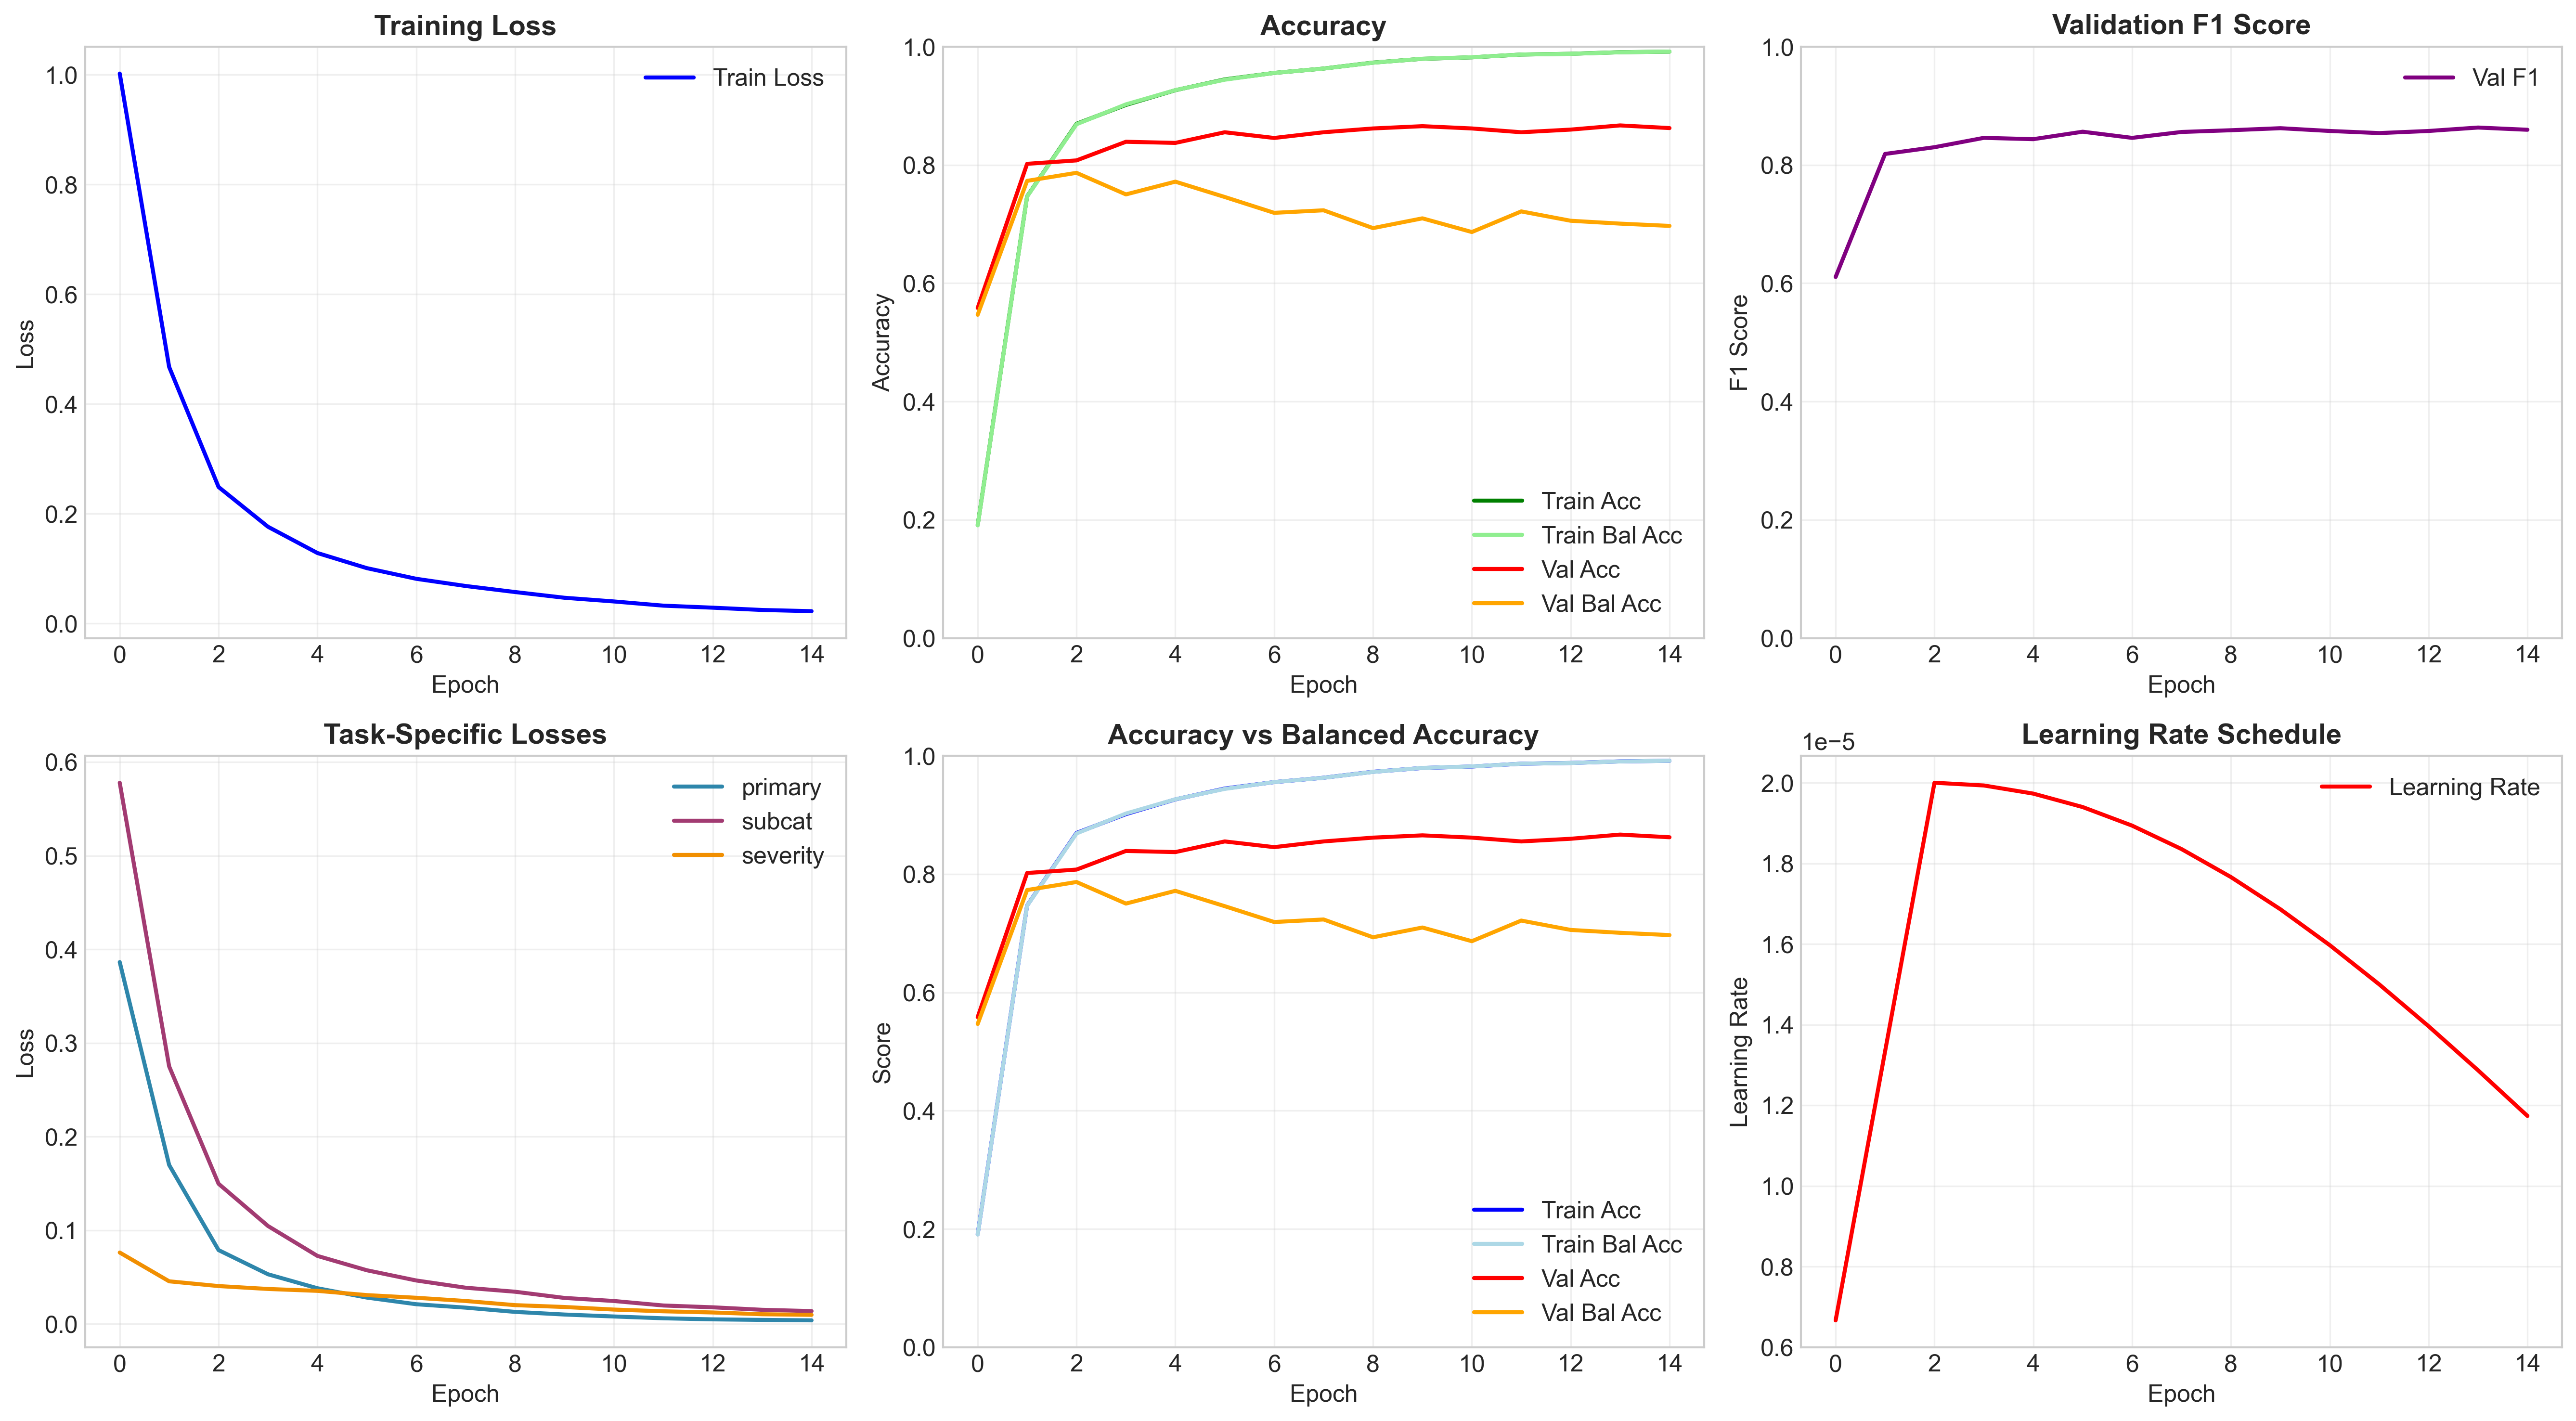

In [35]:
# ============================================================================
# CELL 13: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_training_history(train_history, val_history, save_path=None):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2, color='blue')
    axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Training accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2, color='green')
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2, color='lightgreen')
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2, color='red')
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2, color='orange')
    axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_ylim(0, 1)
    
    # Validation F1
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score', fontsize=14, fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('F1 Score')
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    axes[0, 2].set_ylim(0, 1)
    
    # Task-specific losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task-Specific Losses', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Balanced Accuracy vs Accuracy
    axes[1, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2, color='blue')
    axes[1, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2, color='lightblue')
    axes[1, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2, color='red')
    axes[1, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2, color='orange')
    axes[1, 1].set_title('Accuracy vs Balanced Accuracy', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Score')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    axes[1, 1].set_ylim(0, 1)
    
    # Learning rate
    lrs = [h.get('lr', 0) for h in train_history]
    axes[1, 2].plot(lrs, label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 2].set_xlabel('Epoch')
    axes[1, 2].set_ylabel('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot training history
plot_training_history(
    train_history, val_history,
    save_path=f"{Config.VISUALIZATION_DIR}/training_history.png"
)

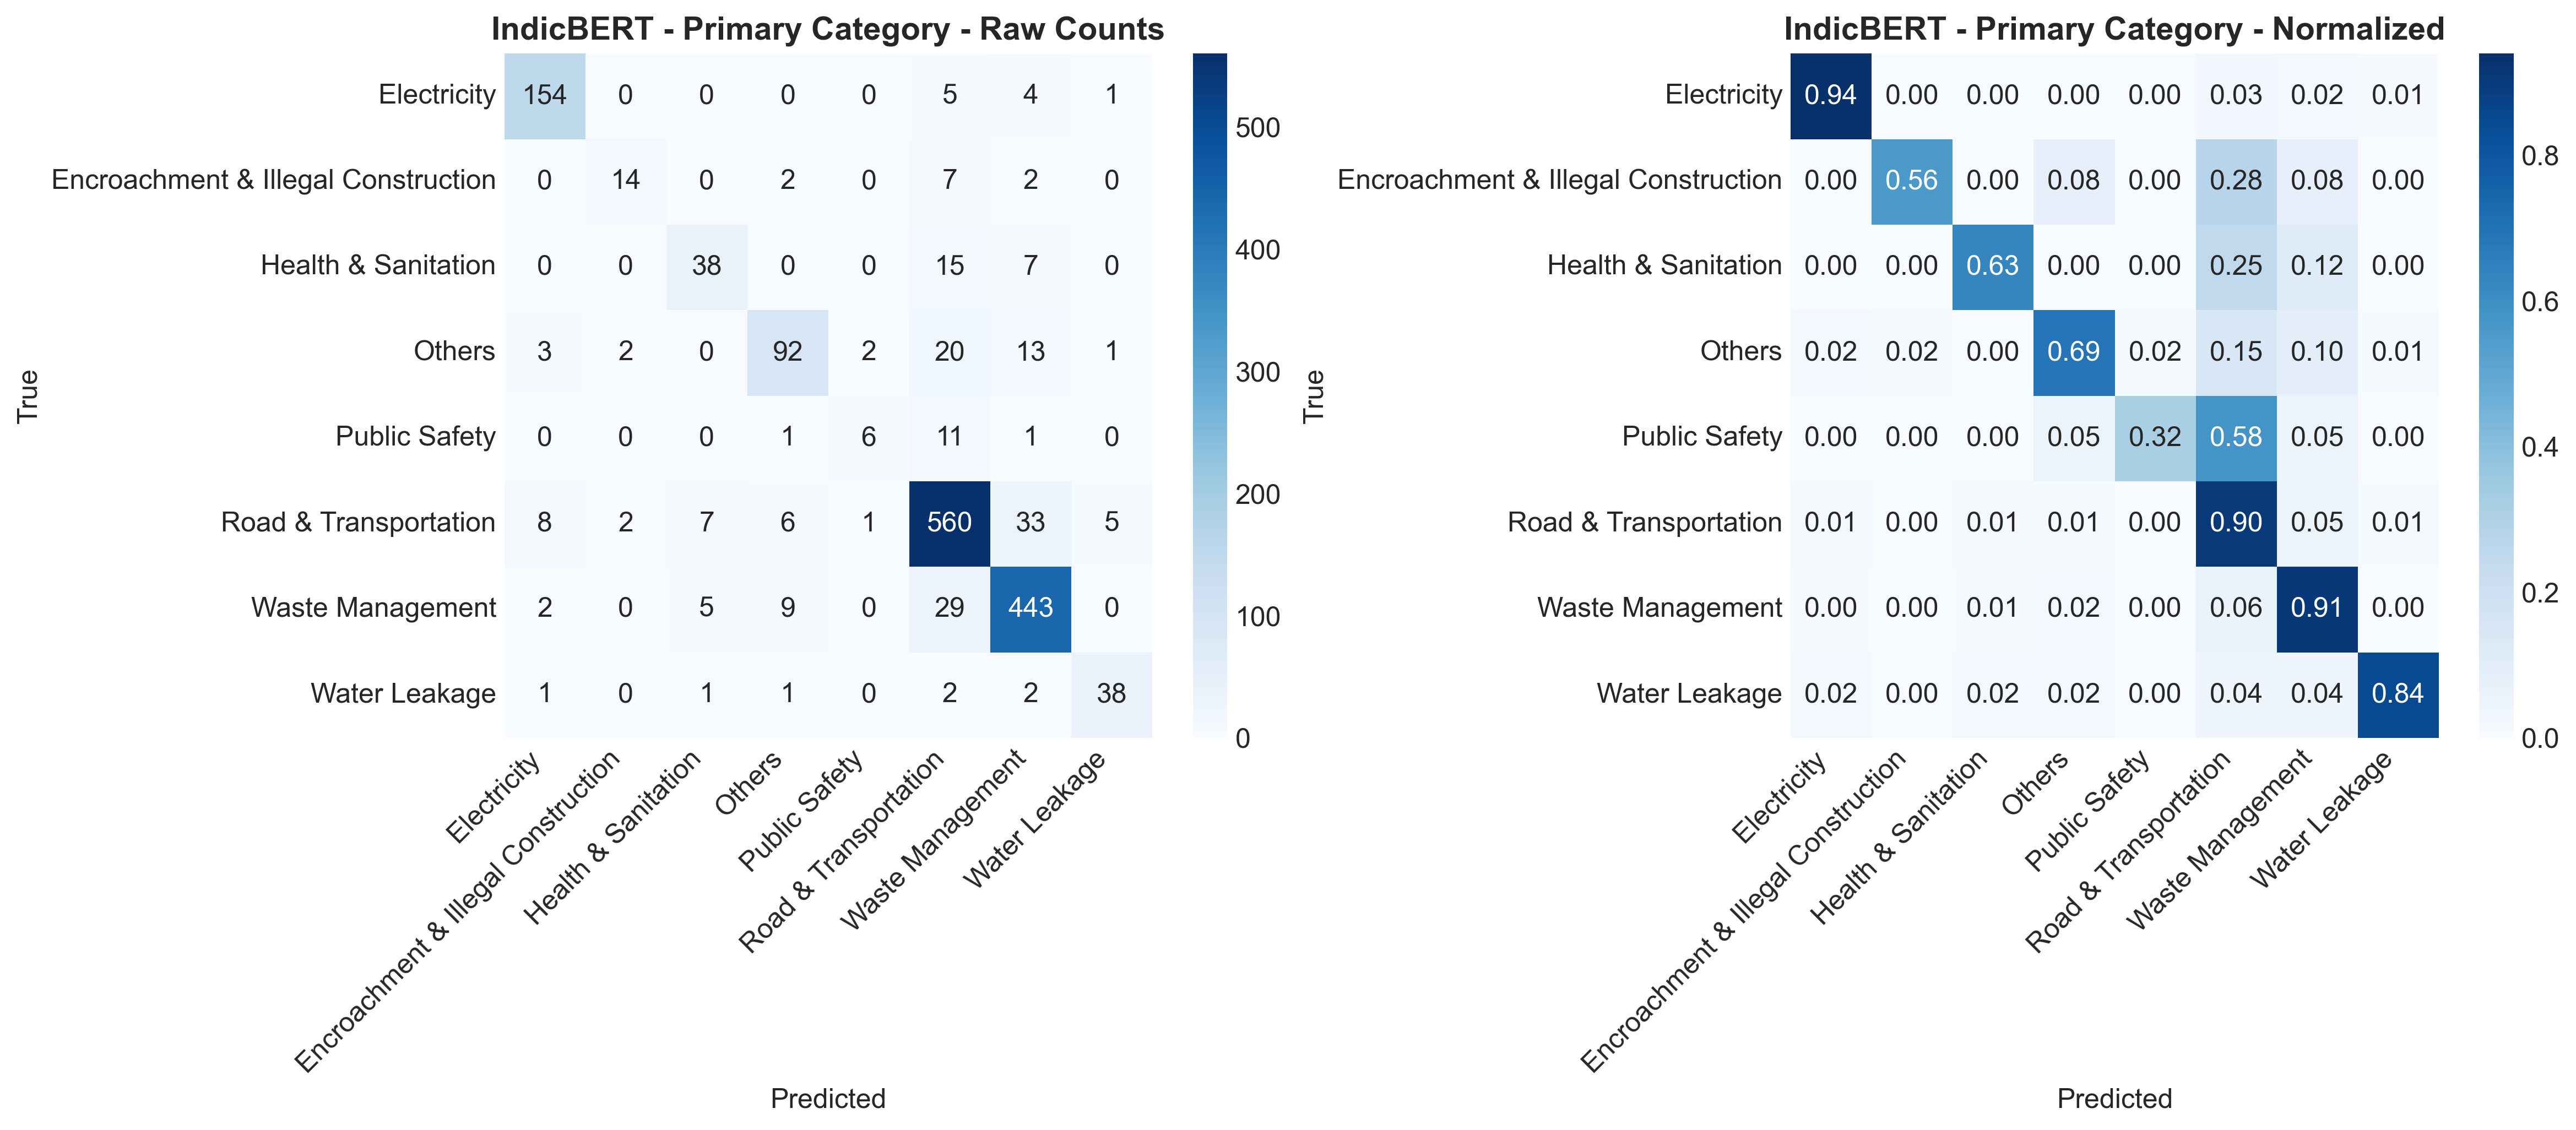

✅ Confusion matrices saved to: indicbert_results/visualizations


In [36]:
# ============================================================================
# CELL 14: CONFUSION MATRIX VISUALIZATION
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    """Plot confusion matrix with raw and normalized versions"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted', fontsize=12)
    axes[0].set_ylabel('True', fontsize=12)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted', fontsize=12)
    axes[1].set_ylabel('True', fontsize=12)
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrices
class_names = preprocessor.le_primary.classes_

plot_confusion_matrix(
    test_labels, test_preds, class_names,
    'IndicBERT - Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

print(f"✅ Confusion matrices saved to: {Config.VISUALIZATION_DIR}")

In [37]:
# ============================================================================
# CELL 15: CLASSIFICATION REPORT
# ============================================================================

def generate_classification_report(y_true, y_pred, class_names, title):
    """Generate and print classification report"""
    print("\n" + "="*80)
    print(f"CLASSIFICATION REPORT - {title}")
    print("="*80)
    print(classification_report(
        y_true, y_pred,
        target_names=class_names,
        digits=4
    ))

# Generate classification reports
generate_classification_report(
    test_labels, test_preds, class_names,
    'IndicBERT - Primary Category'
)

# Save classification report to file
with open(f"{Config.RESULTS_DIR}/classification_report.txt", 'w') as f:
    f.write("CLASSIFICATION REPORT - IndicBERT Primary Category\n")
    f.write("="*80 + "\n\n")
    f.write(classification_report(
        test_labels, test_preds,
        target_names=class_names,
        digits=4
    ))

print(f"\n✅ Classification report saved to: {Config.RESULTS_DIR}/classification_report.txt")


CLASSIFICATION REPORT - IndicBERT - Primary Category
                                     precision    recall  f1-score   support

                        Electricity     0.9167    0.9390    0.9277       164
Encroachment & Illegal Construction     0.7778    0.5600    0.6512        25
                Health & Sanitation     0.7451    0.6333    0.6847        60
                             Others     0.8288    0.6917    0.7541       133
                      Public Safety     0.6667    0.3158    0.4286        19
              Road & Transportation     0.8629    0.9003    0.8812       622
                   Waste Management     0.8772    0.9078    0.8922       488
                      Water Leakage     0.8444    0.8444    0.8444        45

                           accuracy                         0.8644      1556
                          macro avg     0.8149    0.7241    0.7580      1556
                       weighted avg     0.8613    0.8644    0.8608      1556


✅ Classification r

Extracting embeddings for t-SNE...


Extracting embeddings: 100%|██████████| 49/49 [00:09<00:00,  5.38it/s]


Extracted 1556 embeddings of dimension 768
Applying t-SNE...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1556 samples in 0.002s...
[t-SNE] Computed neighbors for 1556 samples in 0.118s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1556
[t-SNE] Computed conditional probabilities for sample 1556 / 1556
[t-SNE] Mean sigma: 1.861305
[t-SNE] KL divergence after 250 iterations with early exaggeration: 62.190460
[t-SNE] KL divergence after 1000 iterations: 0.910407


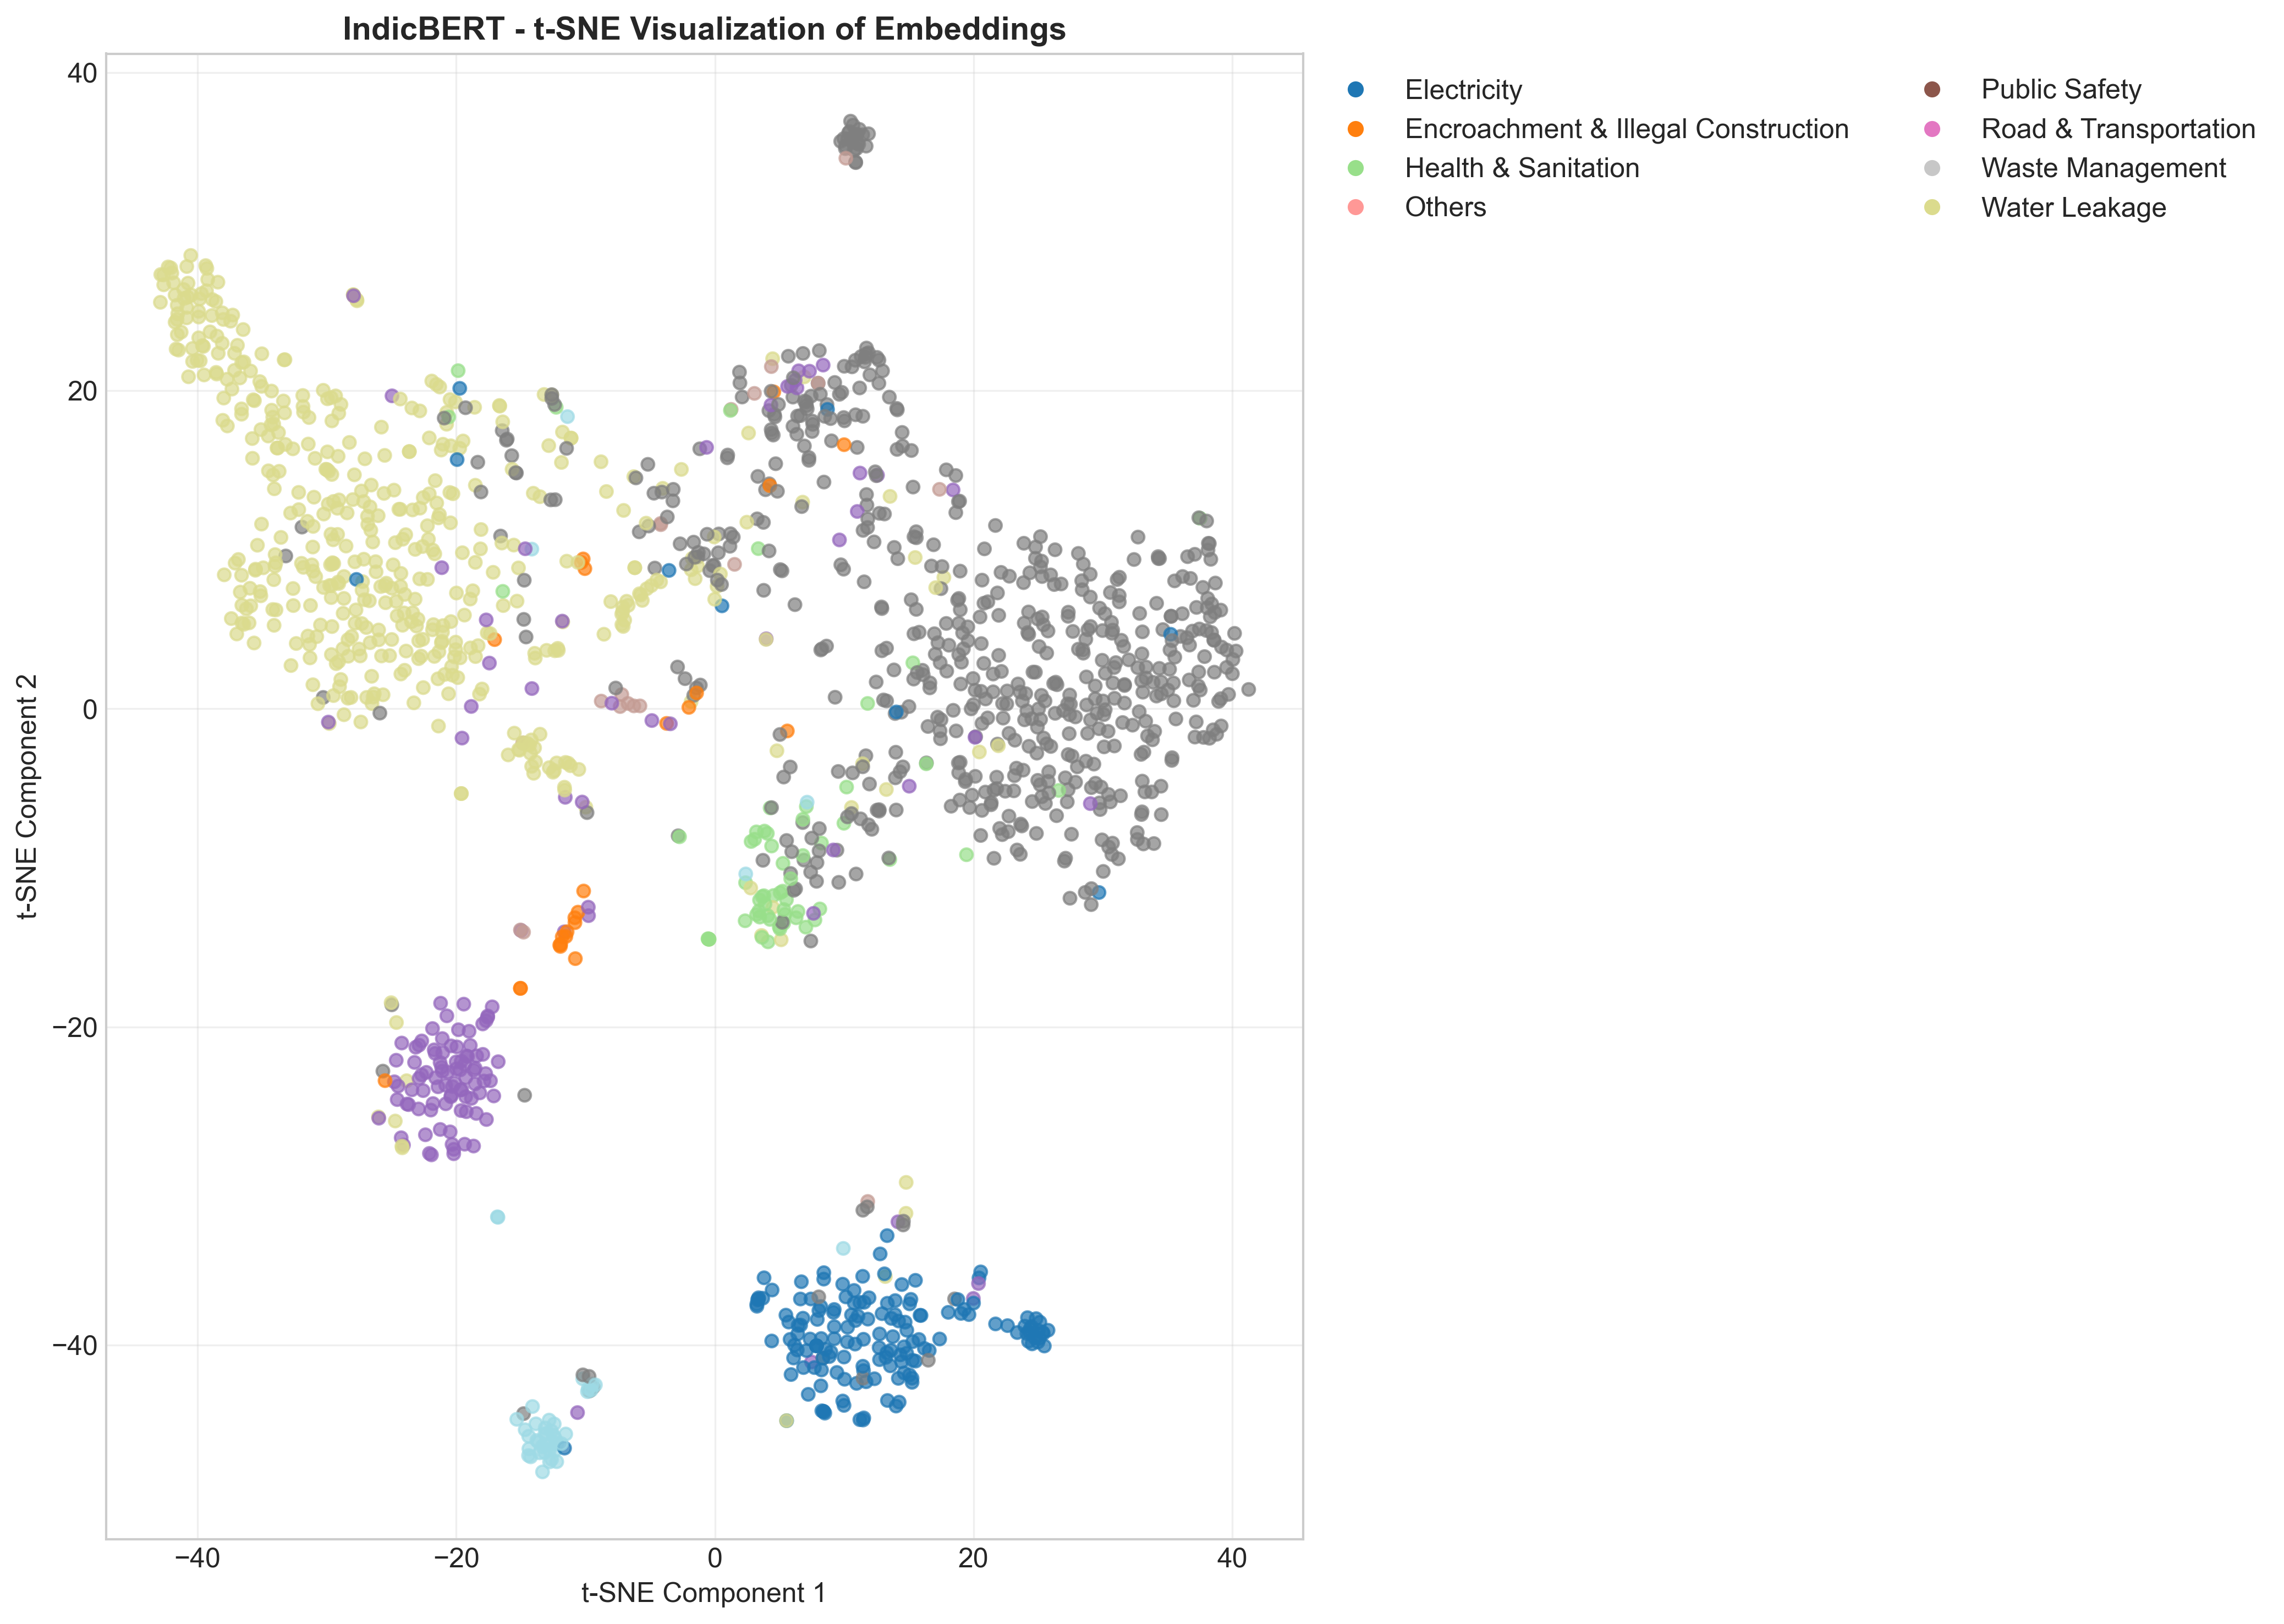

array([[ 37.118275 ,  -1.7846788],
       [-10.820426 , -13.449485 ],
       [-28.676062 ,   8.30775  ],
       ...,
       [ -6.193354 ,   8.861956 ],
       [-19.34604  , -22.358791 ],
       [-21.888672 ,  20.595879 ]], shape=(1556, 2), dtype=float32)

In [39]:
# ============================================================================
# CELL 16: T-SNE EMBEDDING VISUALIZATION
# ============================================================================

def plot_tsne_embeddings(model, test_loader, class_names, device, save_path=None):
    """Create t-SNE visualization of embeddings"""
    print("Extracting embeddings for t-SNE...")
    
    model.eval()
    embeddings = []
    labels = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Extracting embeddings"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            # Get embeddings from the model's base
            # We need to modify this to get actual embeddings
            # For now, we'll use the model's base output
            outputs = model.base(input_ids=input_ids, attention_mask=attention_mask)
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())
            labels.extend(batch['primary'].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    labels = np.array(labels)
    
    print(f"Extracted {embeddings.shape[0]} embeddings of dimension {embeddings.shape[1]}")
    
    # Apply t-SNE
    print("Applying t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, verbose=1)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(14, 10))
    
    scatter = ax.scatter(
        embeddings_2d[:, 0], embeddings_2d[:, 1],
        c=labels, cmap='tab20', alpha=0.7, s=30
    )
    
    ax.set_xlabel('t-SNE Component 1', fontsize=12)
    ax.set_ylabel('t-SNE Component 2', fontsize=12)
    ax.set_title('IndicBERT - t-SNE Visualization of Embeddings', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add legend
    legend_elements = []
    for i, name in enumerate(class_names):
        if i < len(plt.cm.tab20.colors):
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=plt.cm.tab20(i/len(class_names)),
                          label=name, markersize=8)
            )
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), ncol=2)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return embeddings_2d

# Generate t-SNE visualization
plot_tsne_embeddings(
    model, test_loader, class_names, Config.DEVICE,
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png"
)

In [41]:
# ============================================================================
# CELL 17: IMBALANCE IMPACT ANALYSIS (FIXED)
# ============================================================================

def analyze_imbalance_impact(y_true, y_pred, class_names):
    """Analyze the impact of imbalance on per-class performance"""
    
    print("\n" + "="*80)
    print("IMBALANCE IMPACT ANALYSIS")
    print("="*80)
    
    # Convert to numpy arrays if they are lists
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # Per-class metrics
    results = []
    for i, class_name in enumerate(class_names):
        # Binary classification for each class - FIXED: use np.where or astype on numpy array
        y_true_binary = (y_true == i).astype(int)
        y_pred_binary = (y_pred == i).astype(int)
        
        # Calculate metrics
        tp = np.sum((y_true_binary == 1) & (y_pred_binary == 1))
        fp = np.sum((y_true_binary == 0) & (y_pred_binary == 1))
        fn = np.sum((y_true_binary == 1) & (y_pred_binary == 0))
        tn = np.sum((y_true_binary == 0) & (y_pred_binary == 0))
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        
        # Support
        support = np.sum(y_true_binary)
        
        results.append({
            'class': class_name,
            'precision': precision,
            'recall': recall,
            'f1': f1,
            'support': support
        })
    
    # Create DataFrame
    df_results = pd.DataFrame(results)
    
    # Sort by support
    df_results = df_results.sort_values('support', ascending=False)
    
    print("\nPer-Class Performance (Sorted by Support):")
    print(df_results.to_string(index=False))
    
    # Analyze correlation between support and performance
    from scipy.stats import pearsonr
    
    support = df_results['support'].values
    f1_scores = df_results['f1'].values
    
    # Remove classes with zero support
    valid_mask = support > 0
    support_valid = support[valid_mask]
    f1_valid = f1_scores[valid_mask]
    
    if len(support_valid) > 1:
        corr, p_value = pearsonr(support_valid, f1_valid)
        print(f"\nCorrelation between Class Support and F1 Score:")
        print(f"  Pearson Correlation: {corr:.4f}")
        print(f"  P-value: {p_value:.4f}")
        
        if corr > 0.5:
            print("  ⚠️ Strong positive correlation: Imbalanced classes perform worse")
        elif corr < -0.5:
            print("  ✅ Negative correlation: Imbalance handling is working well")
        else:
            print("  ℹ️ Moderate correlation: Imbalance handling is partially effective")
    else:
        print("\n⚠️ Insufficient classes with support > 0 for correlation analysis")
    
    return df_results

# Analyze imbalance impact
df_imbalance = analyze_imbalance_impact(test_labels, test_preds, class_names)

# Save results
df_imbalance.to_csv(f"{Config.RESULTS_DIR}/imbalance_impact_analysis.csv", index=False)
print(f"\n✅ Imbalance analysis saved to: {Config.RESULTS_DIR}/imbalance_impact_analysis.csv")

# Print summary of most affected classes
print("\n" + "="*80)
print("CLASSES MOST AFFECTED BY IMBALANCE")
print("="*80)

# Sort by support (ascending) and show classes with lowest support
df_sorted = df_imbalance.sort_values('support', ascending=True)
print("\nClasses with Lowest Support (Most Imbalanced):")
print(df_sorted[['class', 'support', 'f1']].head(5).to_string(index=False))

# Sort by F1 score (ascending) and show worst performing classes
df_sorted_f1 = df_imbalance.sort_values('f1', ascending=True)
print("\nWorst Performing Classes (Lowest F1-Score):")
print(df_sorted_f1[['class', 'f1', 'support']].head(5).to_string(index=False))

# Calculate average performance by support quartile
print("\nPerformance by Support Quartile:")
support_quartiles = pd.qcut(df_imbalance['support'], q=4, labels=['Q1 (Lowest)', 'Q2', 'Q3', 'Q4 (Highest)'])
quartile_analysis = df_imbalance.groupby(support_quartiles)['f1'].agg(['mean', 'std', 'count']).round(4)
print(quartile_analysis)


IMBALANCE IMPACT ANALYSIS

Per-Class Performance (Sorted by Support):
                              class  precision   recall       f1  support
              Road & Transportation   0.862866 0.900322 0.881196      622
                   Waste Management   0.877228 0.907787 0.892246      488
                        Electricity   0.916667 0.939024 0.927711      164
                             Others   0.828829 0.691729 0.754098      133
                Health & Sanitation   0.745098 0.633333 0.684685       60
                      Water Leakage   0.844444 0.844444 0.844444       45
Encroachment & Illegal Construction   0.777778 0.560000 0.651163       25
                      Public Safety   0.666667 0.315789 0.428571       19

Correlation between Class Support and F1 Score:
  Pearson Correlation: 0.5931
  P-value: 0.1212
  ⚠️ Strong positive correlation: Imbalanced classes perform worse

✅ Imbalance analysis saved to: indicbert_results/results/imbalance_impact_analysis.csv

CLASSES MO

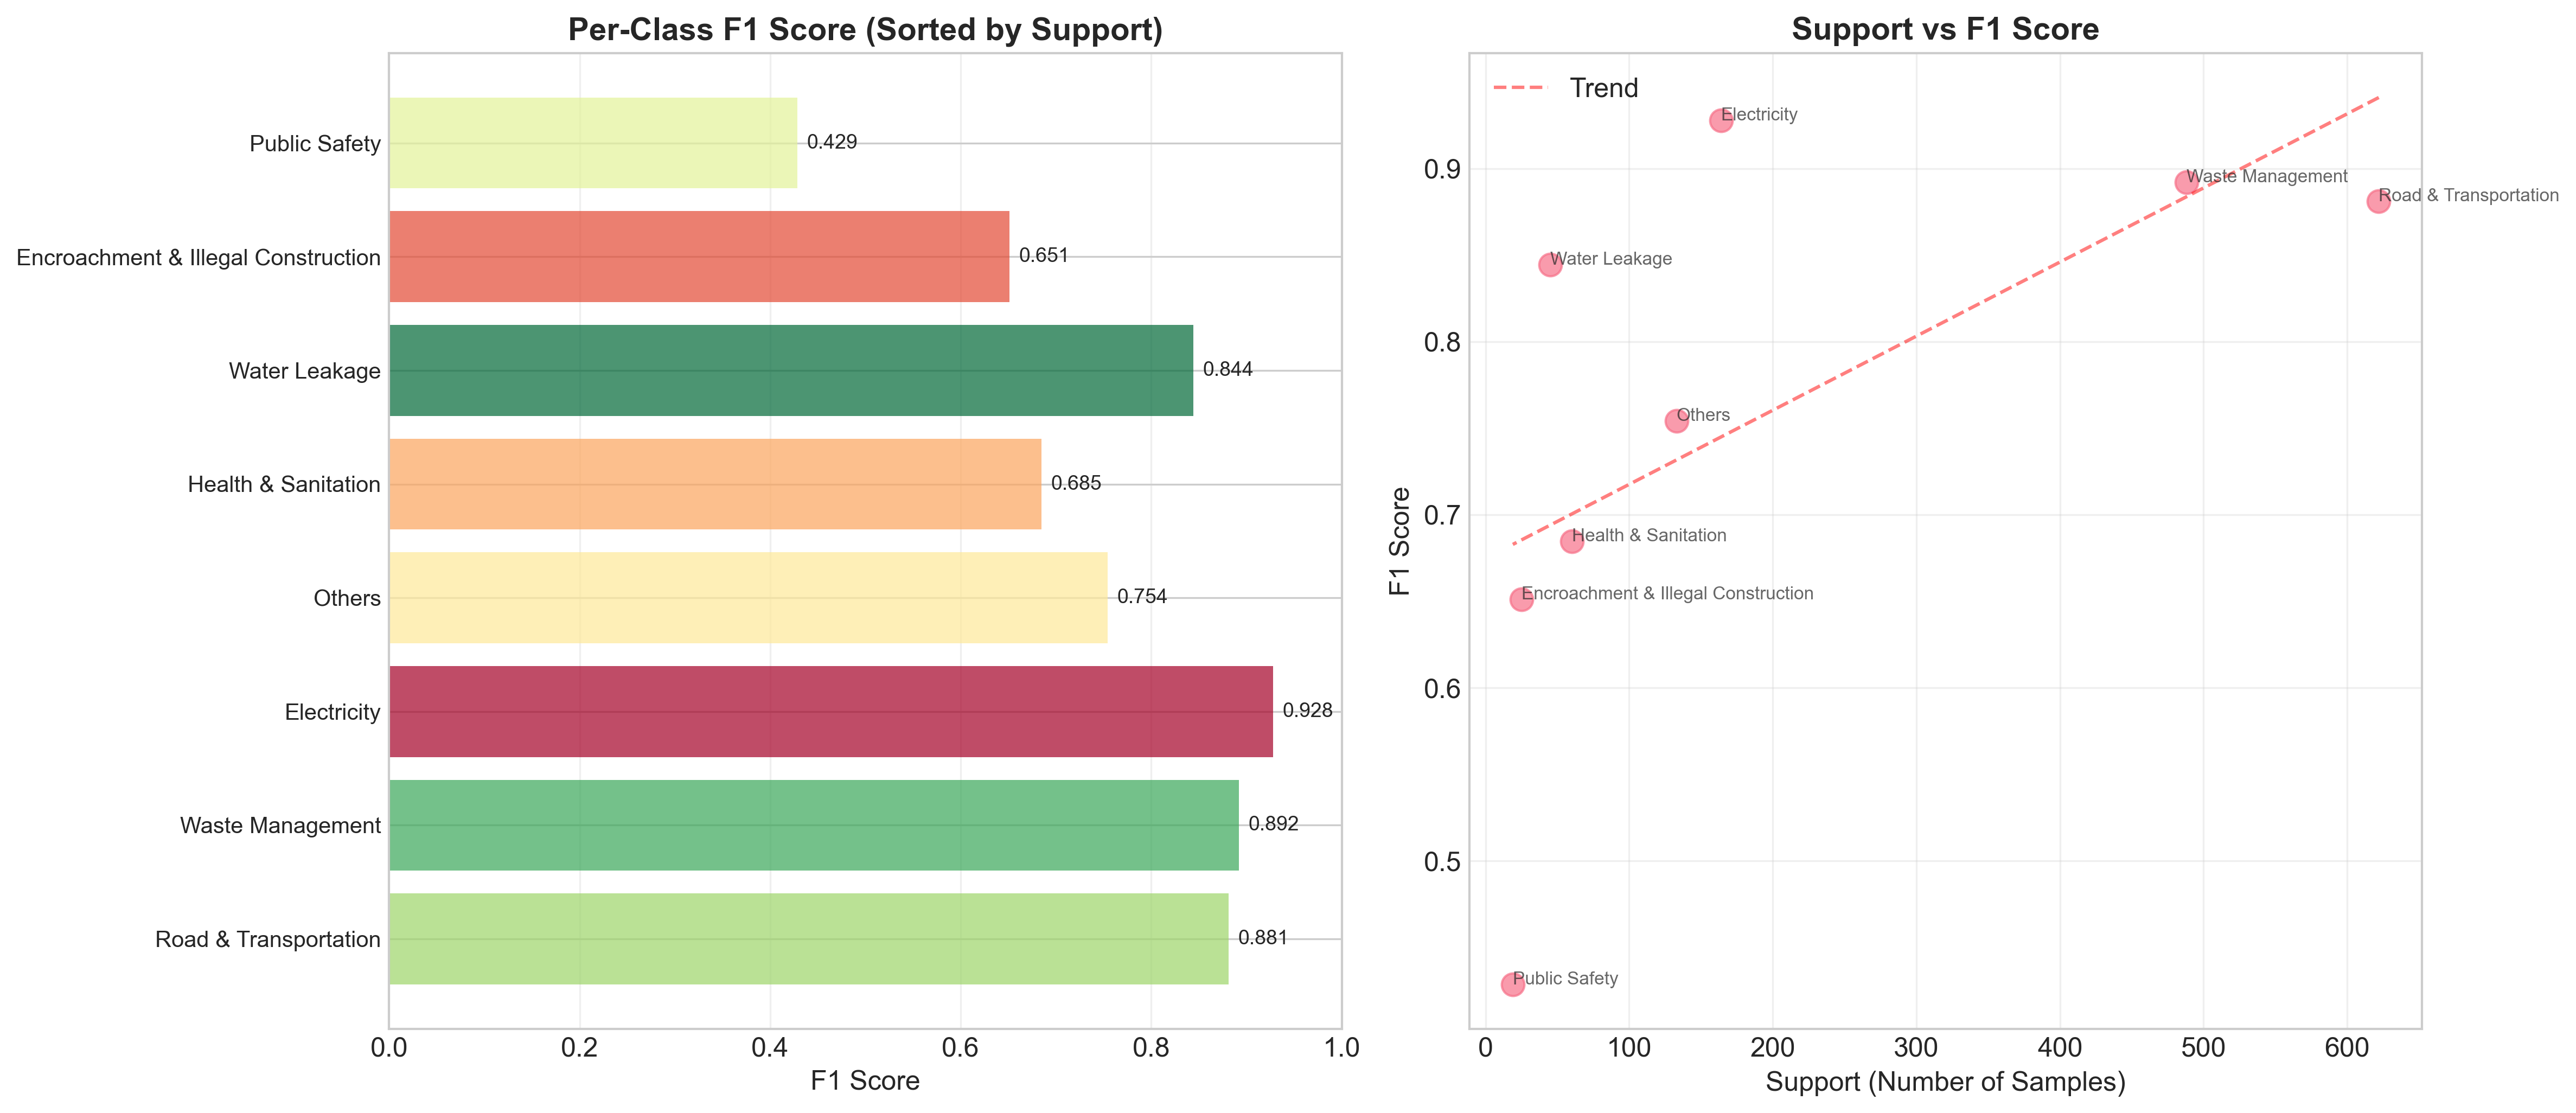

In [42]:
# ============================================================================
# CELL 18: PER-CLASS PERFORMANCE VISUALIZATION
# ============================================================================

def plot_per_class_performance(y_true, y_pred, class_names, save_path=None):
    """Visualize per-class performance metrics"""
    
    # Compute metrics per class
    from sklearn.metrics import precision_recall_fscore_support
    
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, average=None
    )
    
    # Sort by support
    sorted_indices = np.argsort(support)[::-1]
    class_names_sorted = [class_names[i] for i in sorted_indices]
    precision_sorted = [precision[i] for i in sorted_indices]
    recall_sorted = [recall[i] for i in sorted_indices]
    f1_sorted = [f1[i] for i in sorted_indices]
    support_sorted = [support[i] for i in sorted_indices]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # F1 scores
    colors = plt.cm.RdYlGn(np.linspace(0, 1, len(class_names)))[sorted_indices]
    bars = axes[0].barh(range(len(class_names)), f1_sorted, color=colors, alpha=0.7)
    axes[0].set_yticks(range(len(class_names)))
    axes[0].set_yticklabels(class_names_sorted, fontsize=10)
    axes[0].set_xlabel('F1 Score', fontsize=12)
    axes[0].set_title('Per-Class F1 Score (Sorted by Support)', fontsize=14, fontweight='bold')
    axes[0].set_xlim(0, 1)
    axes[0].grid(True, alpha=0.3, axis='x')
    
    # Add value labels
    for bar, val in zip(bars, f1_sorted):
        axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                    f'{val:.3f}', va='center', fontsize=9)
    
    # Support vs F1 scatter
    axes[1].scatter(support_sorted, f1_sorted, alpha=0.7, s=100)
    axes[1].set_xlabel('Support (Number of Samples)', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title('Support vs F1 Score', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    # Add trend line
    z = np.polyfit(support_sorted, f1_sorted, 1)
    p = np.poly1d(z)
    axes[1].plot(support_sorted, p(support_sorted), "r--", alpha=0.5, label='Trend')
    
    # Annotate points
    for i, (x, y, name) in enumerate(zip(support_sorted, f1_sorted, class_names_sorted)):
        axes[1].annotate(name, (x, y), fontsize=8, alpha=0.7)
    
    axes[1].legend()
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot per-class performance
plot_per_class_performance(
    test_labels, test_preds, class_names,
    save_path=f"{Config.VISUALIZATION_DIR}/per_class_performance.png"
)

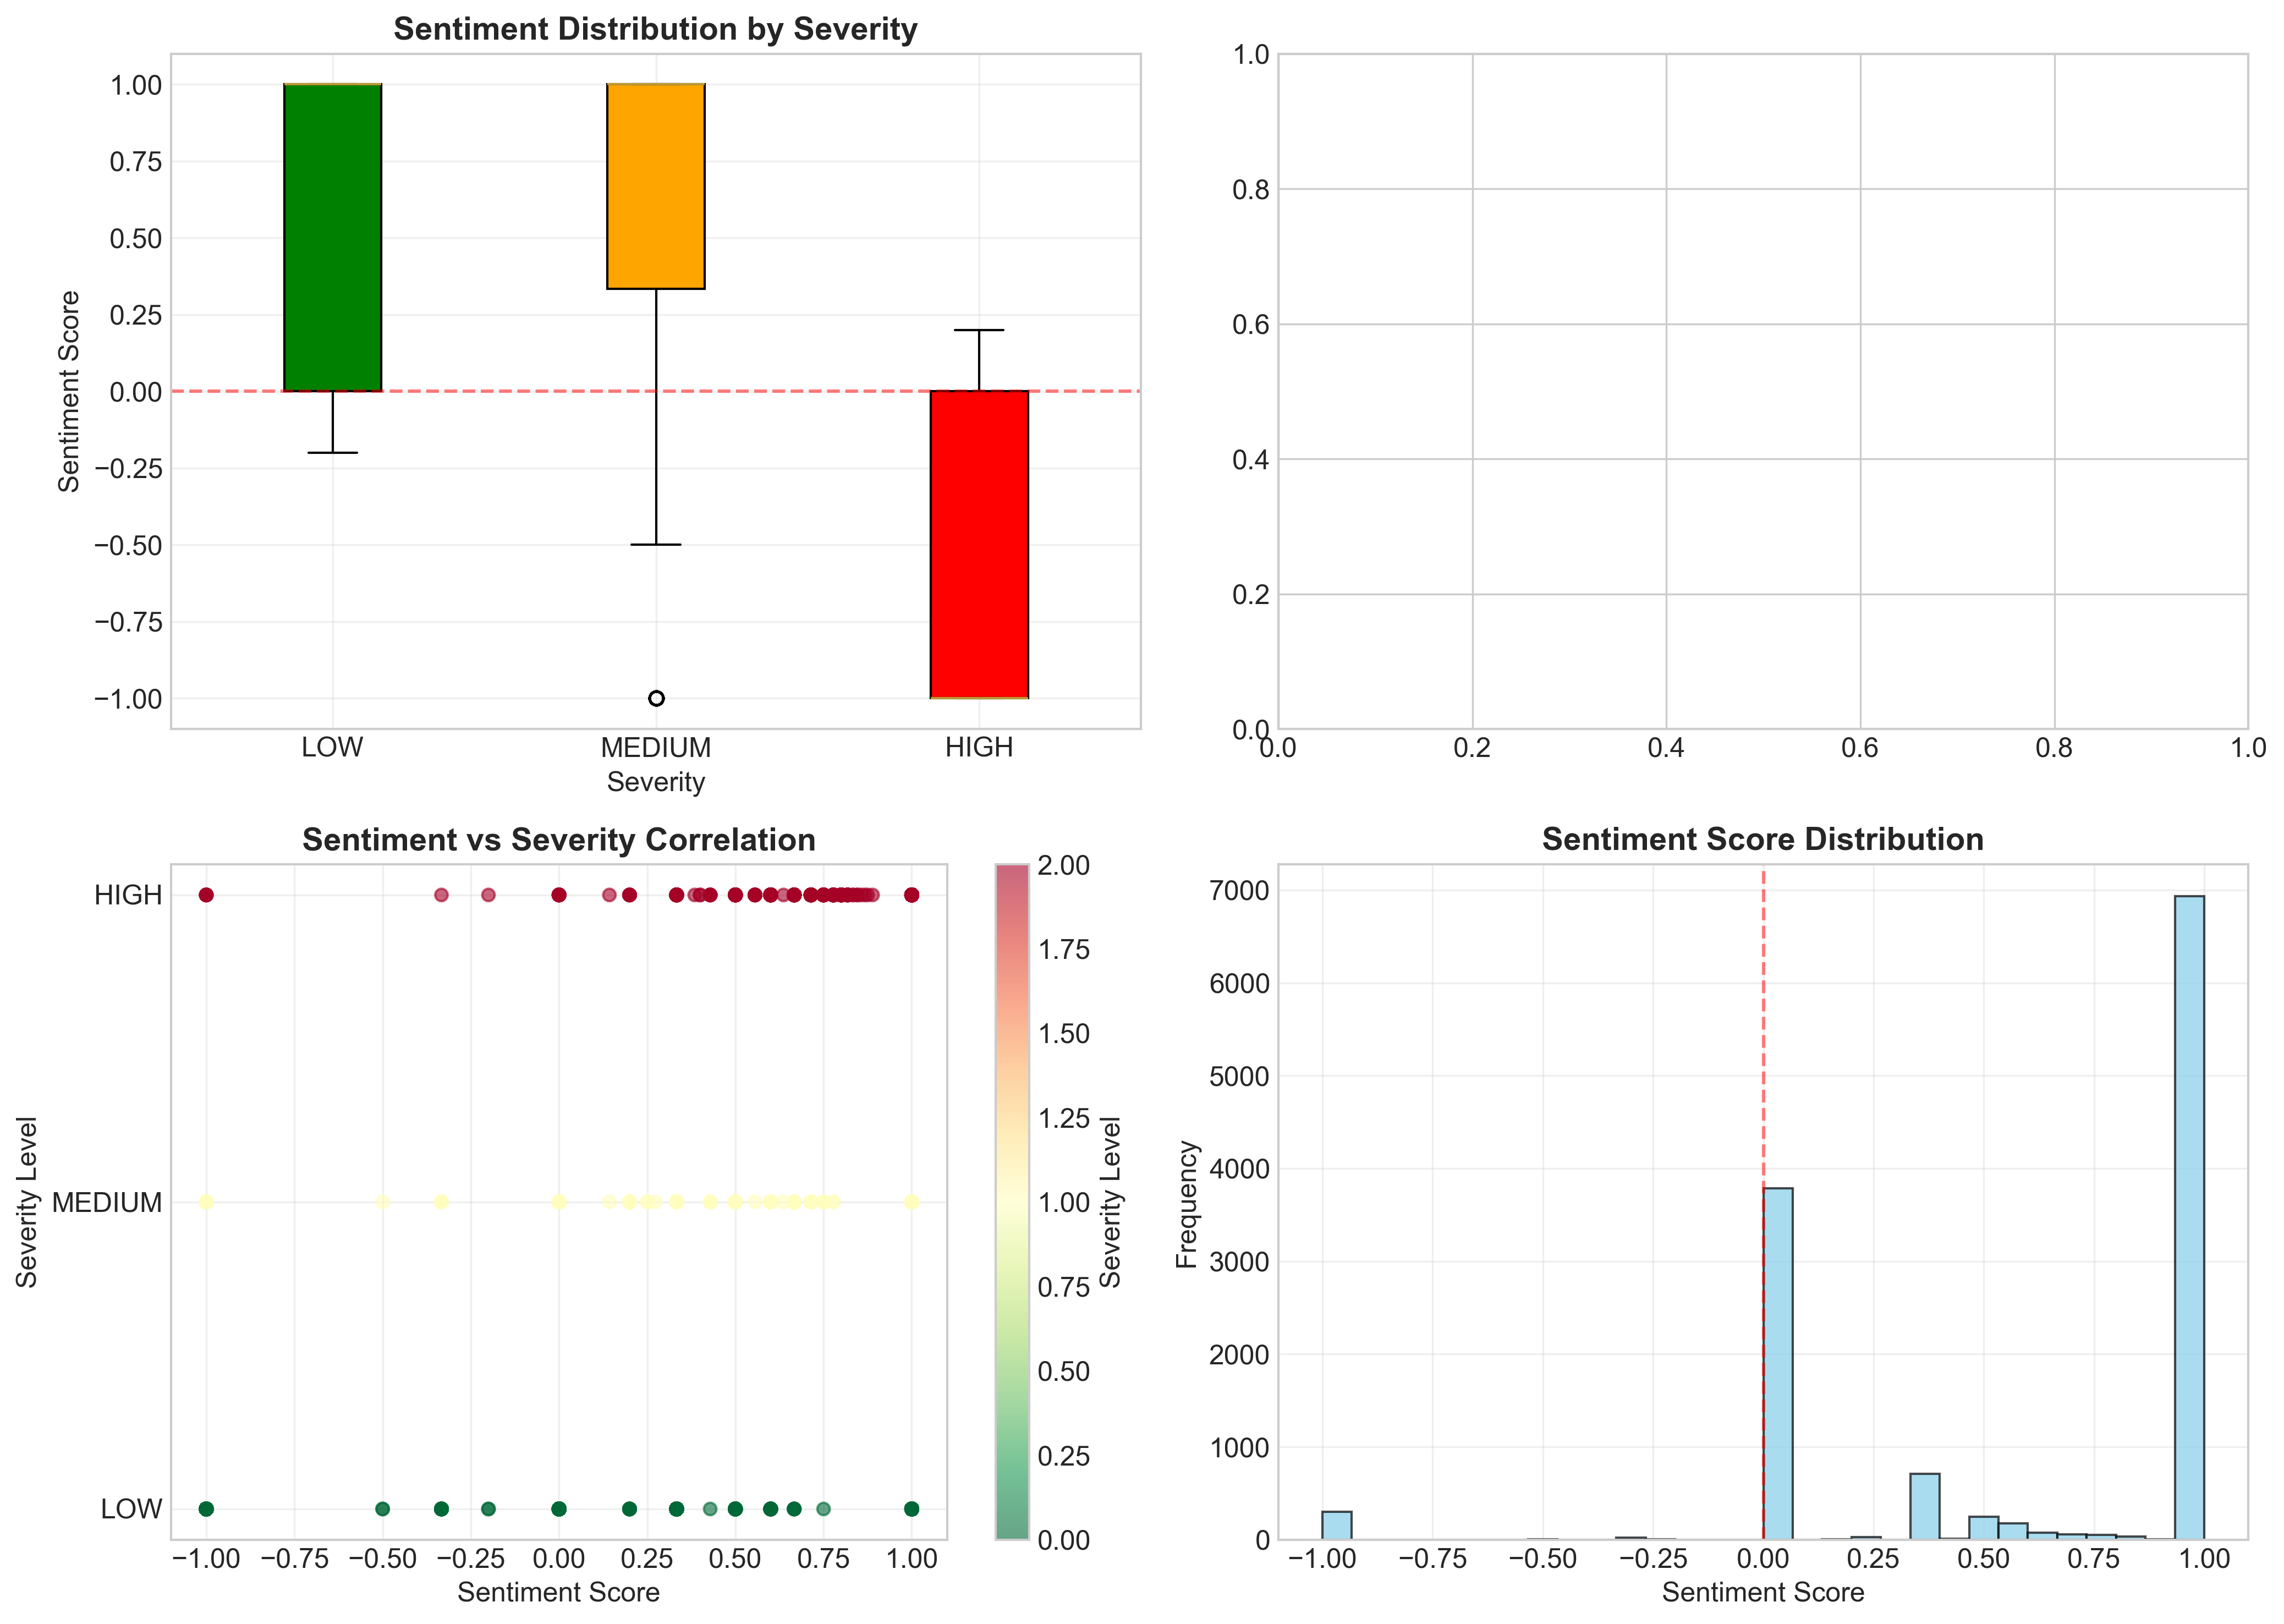

✅ Sentiment analysis saved to: indicbert_results/visualizations/sentiment_analysis.png


In [44]:
# ============================================================================
# CELL 19: SENTIMENT ANALYSIS VISUALIZATION
# ============================================================================

def plot_sentiment_analysis(df, save_path=None):
    """Analyze and visualize sentiment patterns"""
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    
    # 1. Sentiment distribution by severity
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    sentiment_by_severity = [
        df[df['enhanced_severity_label'] == s]['sentiment_score'].values 
        for s in severity_order
    ]
    
    bp = axes[0, 0].boxplot(sentiment_by_severity, labels=severity_order, patch_artist=True)
    colors = ['green', 'orange', 'red']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 0].set_xlabel('Severity', fontsize=12)
    axes[0, 0].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 0].set_title('Sentiment Distribution by Severity', fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Sentiment category distribution
    sentiment_categories = df['sentiment_category'] if 'sentiment_category' in df.columns else None
    if sentiment_categories is not None:
        category_counts = sentiment_categories.value_counts()
        category_order = ['VERY_NEGATIVE', 'NEGATIVE', 'NEUTRAL', 'POSITIVE', 'VERY_POSITIVE']
        counts = [category_counts.get(cat, 0) for cat in category_order]
        colors_bar = ['darkred', 'red', 'gray', 'lightgreen', 'green']
        axes[0, 1].bar(category_order, counts, color=colors_bar, alpha=0.7)
        axes[0, 1].set_xlabel('Sentiment Category', fontsize=12)
        axes[0, 1].set_ylabel('Count', fontsize=12)
        axes[0, 1].set_title('Sentiment Distribution', fontweight='bold')
        axes[0, 1].tick_params(axis='x', rotation=45)
        axes[0, 1].grid(True, alpha=0.3, axis='y')
    
    # 3. Sentiment vs Severity Scatter
    scatter = axes[1, 0].scatter(
        df['sentiment_score'], 
        df['severity_encoded'],
        c=df['severity_encoded'],
        cmap='RdYlGn_r',
        alpha=0.6,
        s=30
    )
    axes[1, 0].set_xlabel('Sentiment Score', fontsize=12)
    axes[1, 0].set_ylabel('Severity Level', fontsize=12)
    axes[1, 0].set_yticks([0, 1, 2])
    axes[1, 0].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
    axes[1, 0].set_title('Sentiment vs Severity Correlation', fontweight='bold')
    axes[1, 0].grid(True, alpha=0.3)
    plt.colorbar(scatter, label='Severity Level', ax=axes[1, 0])
    
    # 4. Sentiment confidence
    if 'sentiment_score' in df.columns:
        axes[1, 1].hist(df['sentiment_score'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
        axes[1, 1].axvline(x=0, color='red', linestyle='--', alpha=0.5)
        axes[1, 1].set_xlabel('Sentiment Score', fontsize=12)
        axes[1, 1].set_ylabel('Frequency', fontsize=12)
        axes[1, 1].set_title('Sentiment Score Distribution', fontweight='bold')
        axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot sentiment analysis (using training data)
plot_sentiment_analysis(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/sentiment_analysis.png"
)

print(f"✅ Sentiment analysis saved to: {Config.VISUALIZATION_DIR}/sentiment_analysis.png")

In [45]:
# ============================================================================
# CELL 20: SUMMARY REPORT GENERATION
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print("INDICBERT COMPREHENSIVE SUMMARY REPORT")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.INDICBERT_PATH}")
    print(f"   Hidden Size: {base_model.config.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # 3. Imbalance Handling
    print("\n3. IMBALANCE HANDLING:")
    print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    if Config.USE_FOCAL_LOSS:
        print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
        print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Gradient Accumulation: {Config.GRADIENT_ACCUMULATION_STEPS}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Training History
    print("\n6. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Best Validation F1: {max([h['val_f1'] for h in val_history]):.4f}")
    print(f"   Best Validation Accuracy: {max([h['val_acc'] for h in val_history]):.4f}")
    
    # 7. Saved Files
    print("\n7. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_indicbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/indicbert_multitask_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Classification Report: {Config.RESULTS_DIR}/classification_report.txt")
    print(f"   Imbalance Analysis: {Config.RESULTS_DIR}/imbalance_impact_analysis.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        # Write all the above information to file
        pass

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")


INDICBERT COMPREHENSIVE SUMMARY REPORT

1. DATASET STATISTICS:
   Training samples: 12441
   Validation samples: 1555
   Test samples: 1556
   Primary categories: 8
   Subcategories: 27
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: ai4bharat/indic-bert
   Hidden Size: 768
   Total Parameters: 33,472,809
   Dropout Rate: 0.3
   Max Sequence Length: 128

3. IMBALANCE HANDLING:
   Class Weights: True
   Focal Loss: True
   Focal Alpha: 0.25
   Focal Gamma: 2.0
   Weighted Sampler: True

4. TRAINING DETAILS:
   Epochs: 15
   Batch Size: 16
   Learning Rate: 2e-05
   Weight Decay: 0.01
   Gradient Accumulation: 2

5. TEST SET PERFORMANCE:
   accuracy: 0.8644
   balanced_accuracy: 0.7241
   f1_macro: 0.7580
   f1_weighted: 0.8608
   precision: 0.8613
   recall: 0.8644
   cohen_kappa: 0.8095
   mcc: 0.8099

6. TRAINING HISTORY:
   Final Train Loss: 0.0226
   Final Train Accuracy: 0.9916
   Best Validation F1: 0.8633
   Best Validation Accuracy: 0.8669

7. SAVED FILES:
   Best 